# Core pipeline: quality control, clustering and annotation

- **Data:** Human Cell Atlas *Census of Immune Cells*, bone marrow (Hay et al.
  2018): eight donors, one 10x lane each (MantonBM1–8).
- **Goal:** raw counts → clean cells → 19 annotated cell types that every later
  stage reuses unchanged (`data/processed/bm_annotated.h5ad`).
- **Code:** `src/load_data`, `src/qc`, `src/preprocess`, `src/cluster`,
  `src/annotate`. Run order: `load_data`, `qc_metrics`, `qc_filter`,
  `doublets`, `doublet_plot`, `doublet_filter`, `preprocess`, `pca`,
  `cluster`, `markers`, `annotate`, `celltypist_check`, then
  `core_pipeline_report` for the summary tables.
- **This notebook** only reads saved tables and figures; nothing is
  recomputed. Each figure links to its full-resolution file.

In [1]:
from io import BytesIO
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display
from PIL import Image as PILImage

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIGURES = ROOT / "figures"
RESULTS = ROOT / "results"
MAX_PIXELS = 1600

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 60)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.precision", 3)


def show(figure: str, width: int = 900) -> None:
    """Saved figure, downscaled for display, with a link to the full file."""
    with PILImage.open(FIGURES / figure) as image:
        image.thumbnail((MAX_PIXELS, MAX_PIXELS * 4))
        buffer = BytesIO()
        image.convert("RGB").save(buffer, format="JPEG", quality=85)
    display(Image(data=buffer.getvalue(), format="jpeg", width=width),
            Markdown(f"[Full-resolution figure](../figures/{figure})"))


def table(name: str, **read_options) -> pd.DataFrame:
    """Saved results table, read from the results directory."""
    return pd.read_csv(RESULTS / name, **read_options)

## 1. Cells and genes kept at each step

In [2]:
table("annotate/core_pipeline_report/core_pipeline_report_steps.csv", index_col="step")

,cells,genes
step,,
merged,44307,33538
qc_filtered,40103,20568
scrublet_removed,39955,20558
top4_removed,38430,20455
annotated,38430,20455


- **44,307 → 38,430 cells (−5,877, 13.3%)** and 33,538 → 20,455 genes.
- **The first cut (`min_genes = 200`) only removes empty droplets.** Real
  thresholds were chosen after looking at the distributions in section 2.
- **Quality control removed 4,204 cells**; doublet removal took 1,673 more in
  two steps — 148 Scrublet calls, then 1,525 by a per-donor top-4% rule
  (section 3).
- **Genes seen in fewer than 3 cells are dropped after each removal**, which is
  why the gene count falls slightly at every step.

In [3]:
table("annotate/core_pipeline_report/core_pipeline_report_donors.csv", index_col="donor")

,merged,qc_filtered,scrublet_removed,top4_removed,annotated
donor,,,,,
MantonBM1,5415,4738,4731,4553,4553
MantonBM2,5625,5376,5273,5073,5073
MantonBM3,5150,4731,4728,4542,4542
MantonBM4,5556,4882,4877,4694,4694
MantonBM5,5411,4790,4768,4582,4582
MantonBM6,5862,5113,5110,4917,4917
MantonBM7,5676,5245,5242,5038,5038
MantonBM8,5612,5228,5226,5031,5031


- **Lanes start evenly sized**: 5,150–5,862 cells after the first cut, and
  4,542–5,073 at the end. No lane is a dud.
- **Quality control removed an uneven share per donor**: 4.4% of MantonBM2
  against 11.5–12.8% of MantonBM1, BM4, BM5 and BM6. The thresholds were set
  on all cells together, so a donor with more stressed or low-quality cells
  loses more.
- **MantonBM2 also had by far the most Scrublet calls** (103 of 148); every
  other donor had 2–22.
- **The top-4% rule removed 178–204 cells per donor**, by design almost the
  same share everywhere (3.7–3.9% of the scored cells).

## 2. Quality control

In [4]:
table("annotate/core_pipeline_report/core_pipeline_report_qc_medians.csv", index_col="donor")

,n_genes_by_counts,total_counts,pct_counts_mt,pct_counts_ribo,pct_counts_hb,pct_counts_in_top_20_genes
donor,,,,,,
MantonBM1,710.0,2156.0,4.019,40.535,0.000,30.168
MantonBM2,739.0,2234.0,3.651,42.171,0.000,29.025
MantonBM3,705.0,2262.5,3.492,39.000,0.000,31.900
MantonBM4,674.0,1811.0,3.571,33.098,0.035,29.182
MantonBM5,655.0,2223.0,3.455,40.114,0.035,31.854
MantonBM6,759.0,2290.5,3.345,40.014,0.000,30.593
MantonBM7,663.0,2052.5,3.238,42.933,0.000,31.355
MantonBM8,662.0,2236.0,3.752,43.995,0.000,31.405


- **Per-donor medians are close**: genes 655–759, counts 1,811–2,291,
  mitochondrial 3.2–4.0%, ribosomal 33–44%, haemoglobin 0.00–0.04%,
  top-20-gene share 29–32%. No donor was dropped and no per-donor thresholds
  were needed.
- **The data is shallow** (about 700 genes and 2,200 counts per median cell).
  A textbook `min_genes = 500` would have removed about a third of all cells,
  so thresholds were set from the data instead.
- **Ribosomal reads are about 40% of a typical cell.** High, but normal for
  marrow, which is full of growing progenitors. Not filtered on.
- **Median haemoglobin is near zero**, so free red-cell RNA in the droplets is
  low; the haemoglobin tails come from real red-cell precursors.

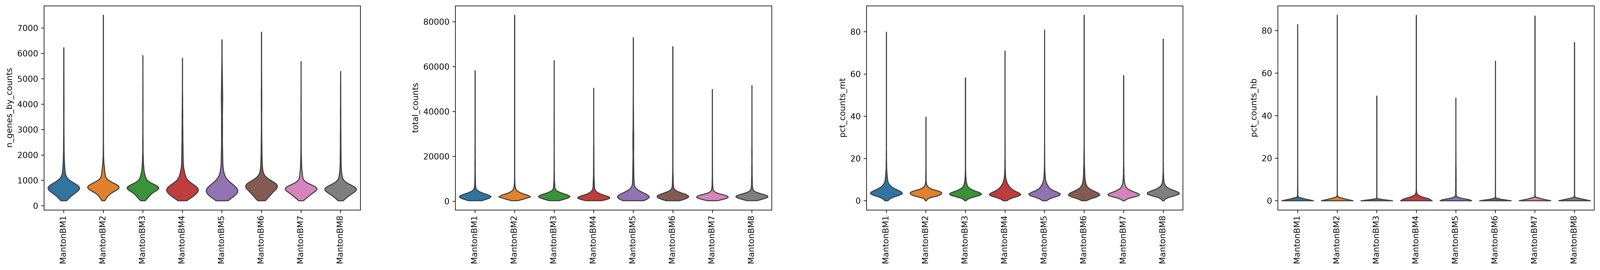

[Full-resolution figure](../figures/qc/qc_metrics/violin_by_donor.png)

In [5]:
show("qc/qc_metrics/violin_by_donor.png")

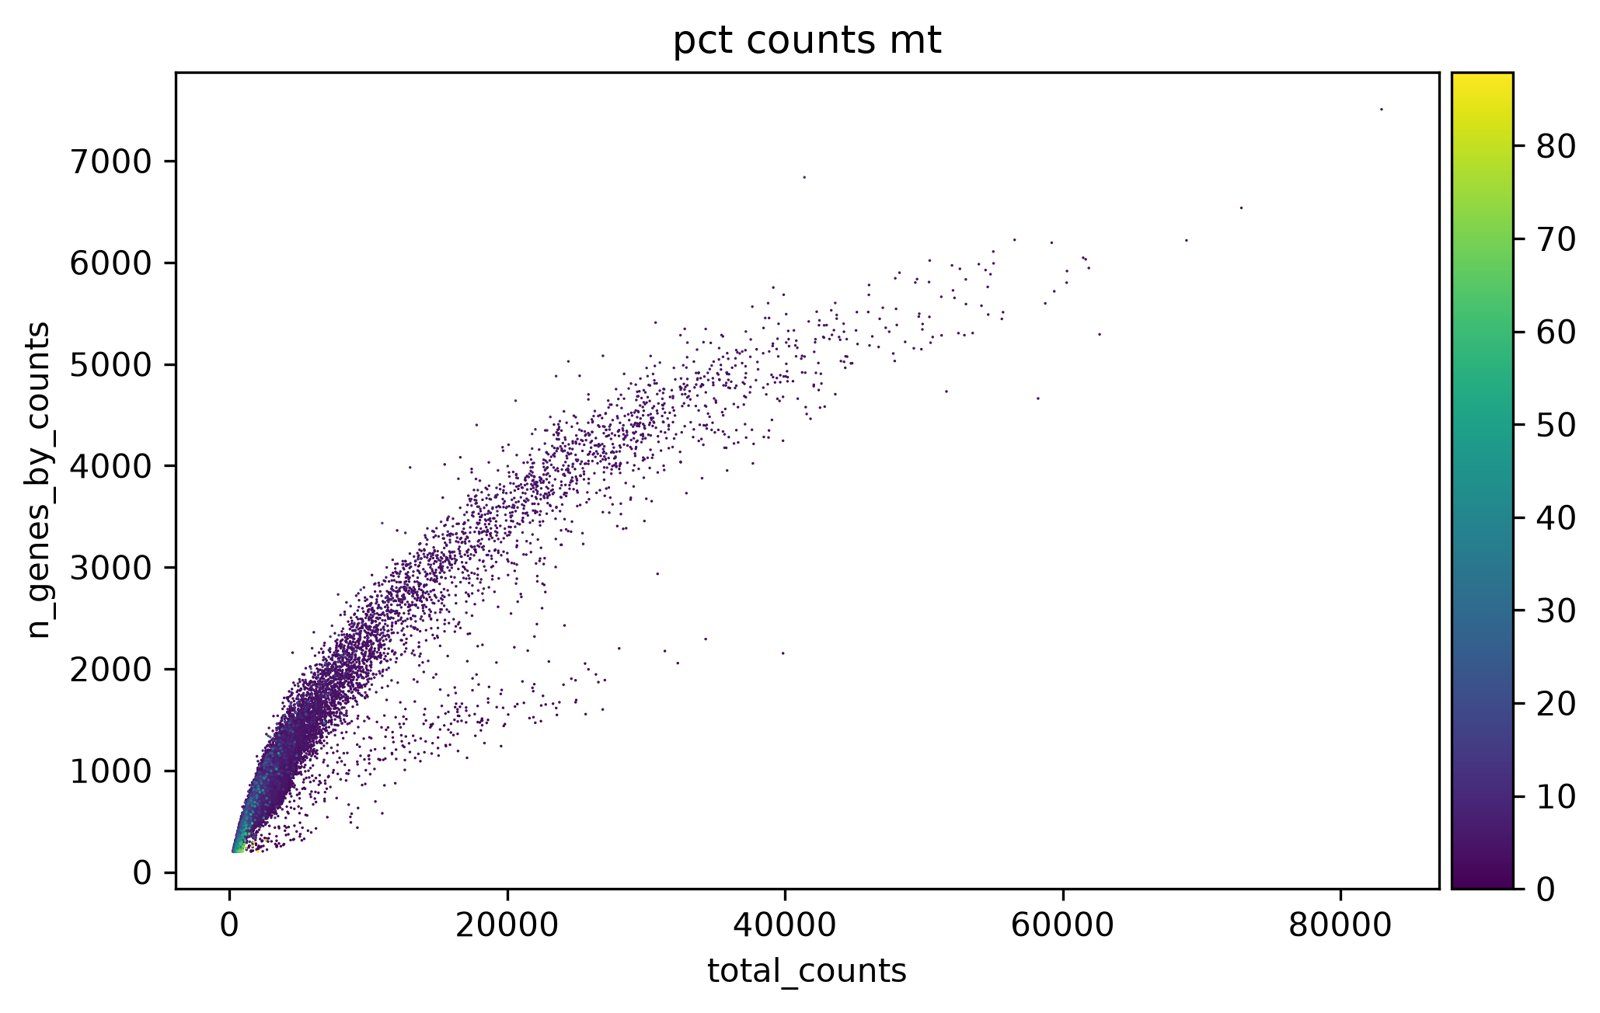

[Full-resolution figure](../figures/qc/qc_metrics/scatter_counts_vs_genes.png)

In [6]:
show("qc/qc_metrics/scatter_counts_vs_genes.png", width=650)

- **All eight donors have the same shape** on every metric (all 44,307 merged
  cells shown, before filtering).
- **Long upper tails exist in every donor**: up to about 7,500 genes, 80,000
  counts and 85% mitochondrial reads. These are the cells the rules below
  act on.
- **The scatter has two arms.** The main arm rises steadily (more counts, more
  genes). A second, lower arm holds cells with 20,000–40,000 counts but only
  1,000–2,000 genes: reads piled into a few genes, mostly haemoglobin — red-cell
  precursors, not damaged cells.
- **High-mitochondrial cells (green–yellow) sit in the bottom-left corner**:
  few counts, few genes, mostly mitochondrial reads — the dying-cell signature.

In [7]:
rules = table("annotate/core_pipeline_report/core_pipeline_report_qc_rules.csv", index_col="rule")
rules

,metric,n_mads,side,floor,removes,bound,cells_flagged
rule,,,,,,,
low counts,log1p_total_counts,5,low,-inf,True,5.855,160
low genes,log1p_n_genes_by_counts,5,low,-inf,True,5.362,286
high top-20 share,pct_counts_in_top_20_genes,5,high,-inf,True,46.114,1373
high mitochondrial,pct_counts_mt,3,high,8.0,True,6.907,3386
high complexity,log1p_n_genes_by_counts,5,high,-inf,False,7.731,1986


- **Rules use median absolute deviations (MADs)** — how many typical spreads a
  cell sits from the median. `bound` is the cut on the metric's own scale
  (log1p for counts and genes).
- **Low counts** (below about 348) flagged 160 cells; **low genes** (below
  about 212) flagged 286; **top-20-gene share** above 46.1% flagged 1,373.
- **Mitochondrial share was the main cause: 3,386 cells.** The rule needs both
  a 3-MAD outlier (above 6.9%) *and* a floor of 8%, so the effective cut is 8%
  and ordinary cells at 5–6% survive.
- **5 MADs, not 3, on counts, genes and the top-20 share**: at 3 MADs the upper
  gene cut would have fallen near 1,400 genes and removed real large
  progenitors.
- **High-complexity cells were flagged, not removed**: 1,986 cells above about
  2,277 genes; 60 of them fell to other rules, leaving 1,926. They later proved
  to be the early erythroid lineage (section 5) — a standard upper cut would
  have deleted that lineage.
- **The flags overlap**, so they do not add up to the 4,204 removed.
- **No filter on ribosomal or haemoglobin share**: both are biology in marrow.

## 3. Doublets

In [8]:
table("annotate/core_pipeline_report/core_pipeline_report_doublets.csv", index_col="donor")

,cells_scored,scrublet_threshold,scrublet_calls,top4_cutoff,top4_removed
donor,,,,,
MantonBM1,4738,0.512,7,0.156,178
MantonBM2,5376,0.258,103,0.122,200
MantonBM3,4731,0.523,3,0.145,186
MantonBM4,4882,0.524,5,0.130,183
MantonBM5,4790,0.385,22,0.109,186
MantonBM6,5113,0.533,3,0.143,193
MantonBM7,5245,0.545,3,0.164,204
MantonBM8,5228,0.534,2,0.153,195


- **Scrublet was run per donor**, so it never simulates doublets between cells
  of different donors, which could not exist.
- **Its automatic threshold failed on all eight lanes.** It called 148 cells
  (0.37%) against an expected 3–6%. Thresholds landed at 0.26–0.55, far out in
  the tail; MantonBM2 got 103 calls (1.9%) and MantonBM8 only 2.
- **Both removals were applied**: Scrublet's own 148 calls first, then the
  top 4% of the remaining cells per donor (cutoff `top4_cutoff`, 0.109 in
  MantonBM5 to 0.164 in MantonBM7).
- **Why 4%:** the expected 10x doublet rate at about 5,000 recovered cells.

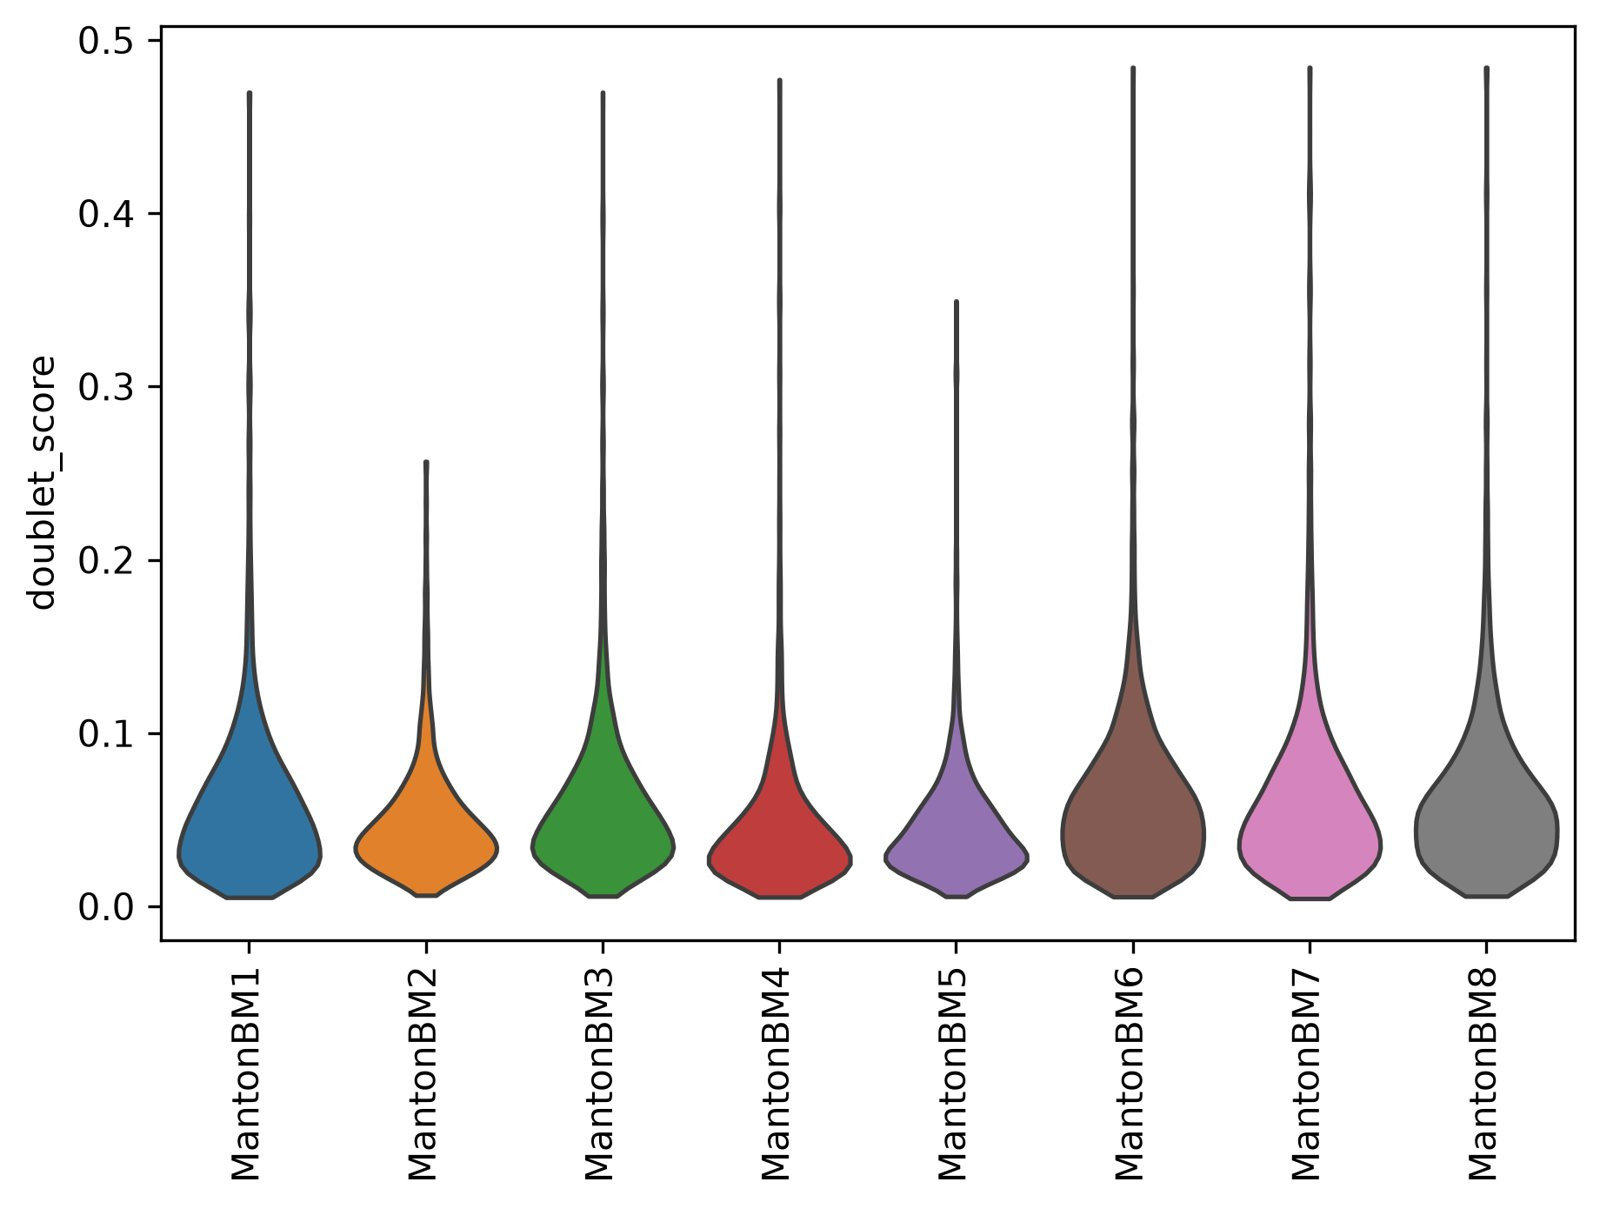

[Full-resolution figure](../figures/qc/doublets/violin_doublet_score.png)

In [9]:
show("qc/doublets/violin_doublet_score.png", width=650)

- **Scores per donor.** Most cells score below 0.1 in every donor.
- **Each donor's tail ends just below its automatic threshold**, consistent
  with the figure showing the 39,955 cells left after Scrublet's calls were
  removed: MantonBM2 tops out near 0.26 and MantonBM5
  near 0.35, matching their low thresholds (0.258 and 0.385).

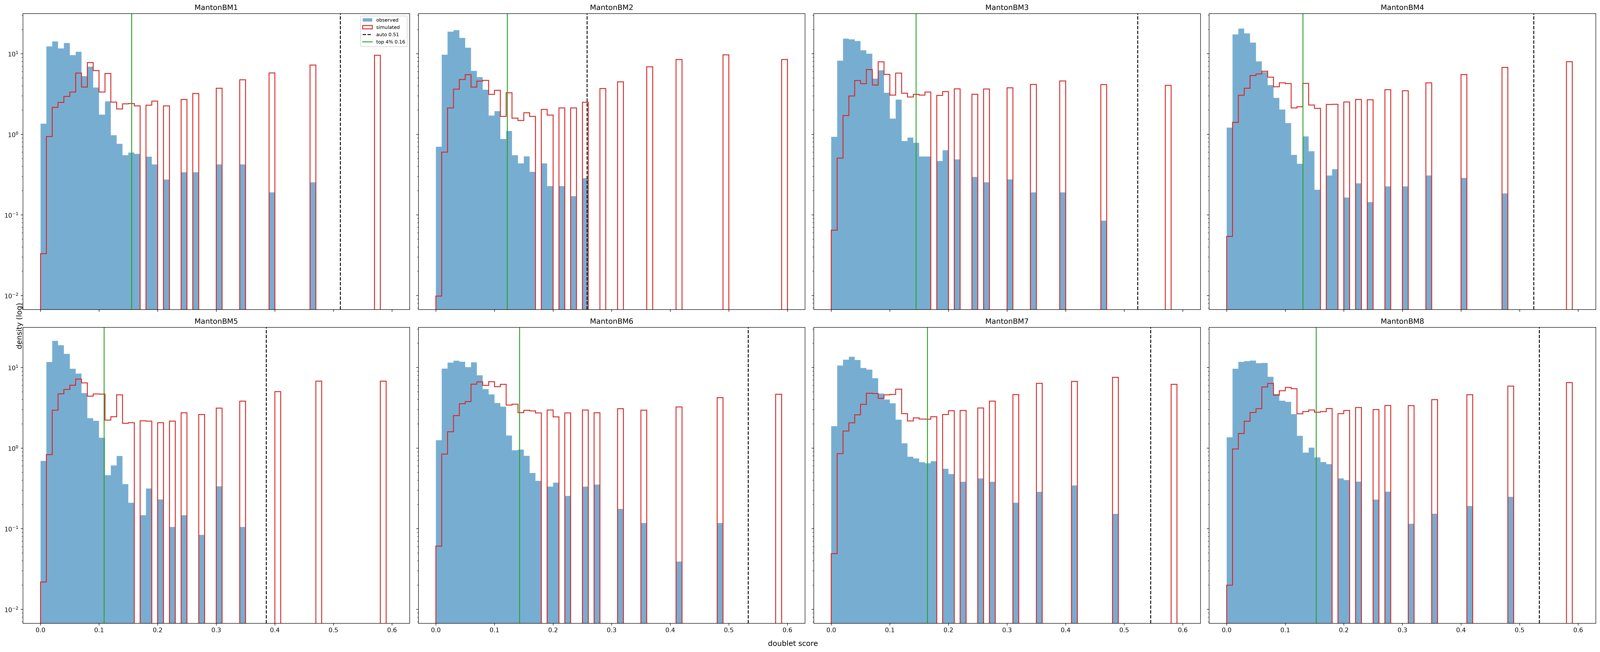

[Full-resolution figure](../figures/qc/doublet_plot/doublet_score_distribution.png)

In [10]:
show("qc/doublet_plot/doublet_score_distribution.png")

- **Blue: observed cells; red: Scrublet's simulated doublets; dashed black:
  automatic threshold; green: the top-4% cutoff** (log density axis).
- **Why the automatic threshold failed:** the simulated scores have one hump
  near 0.05–0.1 and then a long flat plateau out to 0.6. Scrublet looks for a
  dip between two humps; with no dip it lands in the far tail.
- **The green line sits where the simulated density overtakes the observed
  one** (about 0.11–0.16): cells to its right look more like synthetic doublets
  than like typical cells. That is the justification for the cutoff.
- **The spiky bars are real, not a plotting fault**: Scrublet's score is
  built from nearest-neighbour fractions and takes a limited set of values.

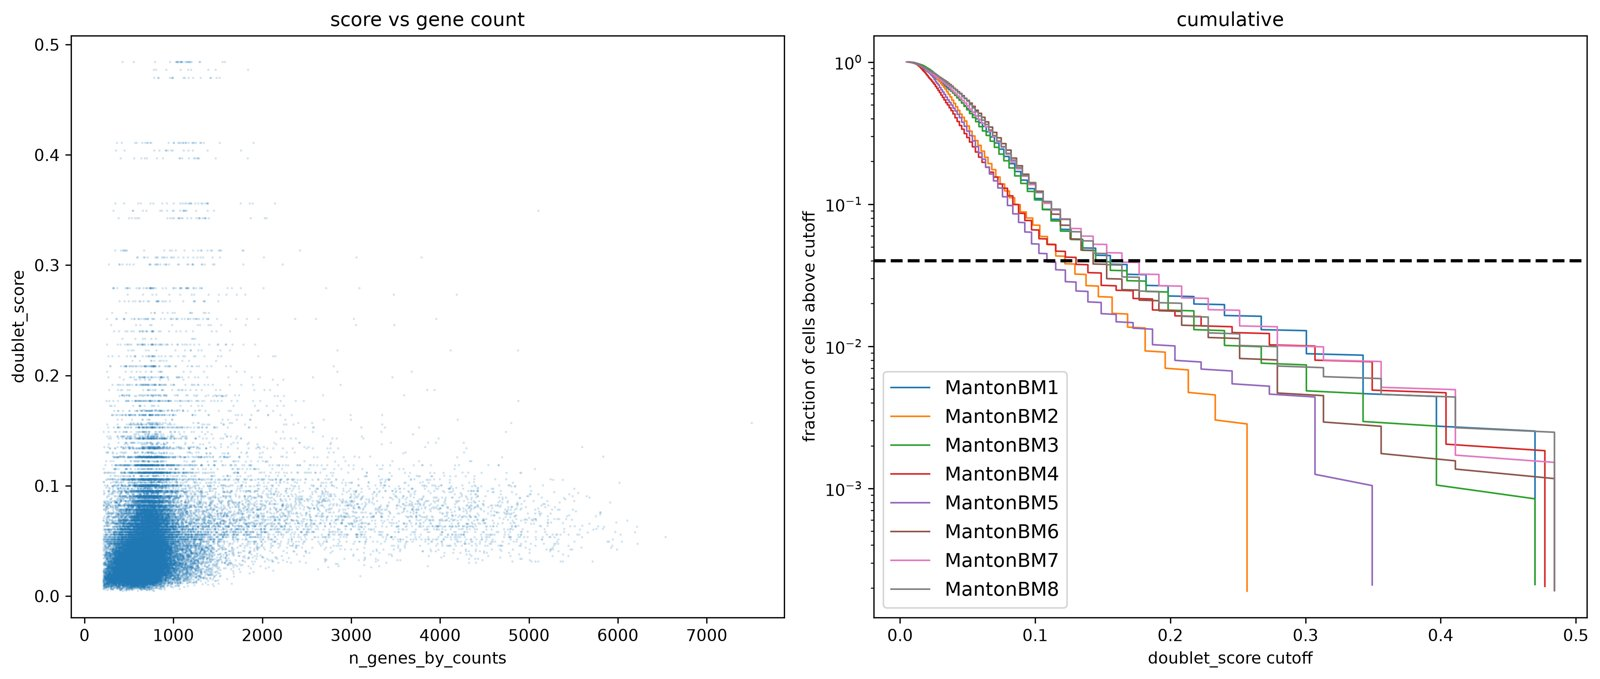

[Full-resolution figure](../figures/qc/doublet_plot/doublet_checks.png)

In [11]:
show("qc/doublet_plot/doublet_checks.png")

- **Left — score against gene count.** High-scoring cells sit at about
  1,000–1,500 genes, where two typical 700-gene cells would land. The
  horizontal stripes are the same discrete score values as above.
- **The very high-gene cells (3,000–6,000 genes) mostly score low**: Scrublet
  sees them as large real cells, not mixtures. Of the 1,926 kept
  high-complexity cells, its automatic run called only 4.
- **Right — fraction of cells above each cutoff, per donor.** The curves
  separate in the tail: MantonBM2 and MantonBM5 cross the 4% line (dashed) near
  0.11, the others near 0.13–0.16. One shared cutoff would over-cut those two
  donors, so the rule is per donor.

## 4. Normalisation, variable genes and PCA

In [12]:
hvg = table("annotate/core_pipeline_report/core_pipeline_report_hvg.csv", index_col=0)
display(hvg[["mt", "ribo", "hb"]].sum().rename("genes among the 2,000"))
hvg.head(20)

mt       6
ribo    10
hb       9
Name: genes among the 2,000, dtype: int64

,highly_variable_rank,highly_variable_nbatches,means,variances_norm,mt,ribo,hb
HBB,0.0,8,53.778,26.791,False,False,True
HBA1,1.5,8,10.724,21.945,False,False,True
HBA2,2.0,8,8.967,21.533,False,False,True
CA1,4.0,8,2.521,15.277,False,False,False
HBD,5.0,8,2.244,14.706,False,False,True
AHSP,6.0,8,3.327,15.518,False,False,False
HBM,6.5,8,0.583,13.298,False,False,True
ELANE,8.0,8,0.229,10.488,False,False,False
MPO,8.0,8,0.424,11.265,False,False,False
PRTN3,9.5,8,0.201,10.342,False,False,False


- **Raw counts were stored before normalising** (`layers["counts"]`), because
  scVI, Pearson residuals, GLM-PCA and deconvolution need them later.
- **Normalised to 10,000 counts per cell, then log1p.**
- **2,000 variable genes** (`seurat_v3`, ranked within each donor and then
  combined). `highly_variable_nbatches`: 746 genes are variable in all eight
  donors, 492 in only one.
- **Only 10 ribosomal, 6 mitochondrial and 9 haemoglobin genes made the
  list** — ranking per donor kept ribosomal genes out.
- **The top 20 are three marrow lineages at once**: red-cell precursors (HBB,
  HBA1, HBA2, HBD, HBM, AHSP, CA1, CA2, ALAS2, GYPA, BLVRB, PRDX2, FAM178B),
  early neutrophils (ELANE, MPO, PRTN3, AZU1), early B cells (DNTT, IGLL1),
  and dividing cells (HIST1H4C).
- **All 9 haemoglobin genes are variable, and that is correct here**: median
  haemoglobin is near zero, so they mark a real red-cell lineage, not
  contamination.

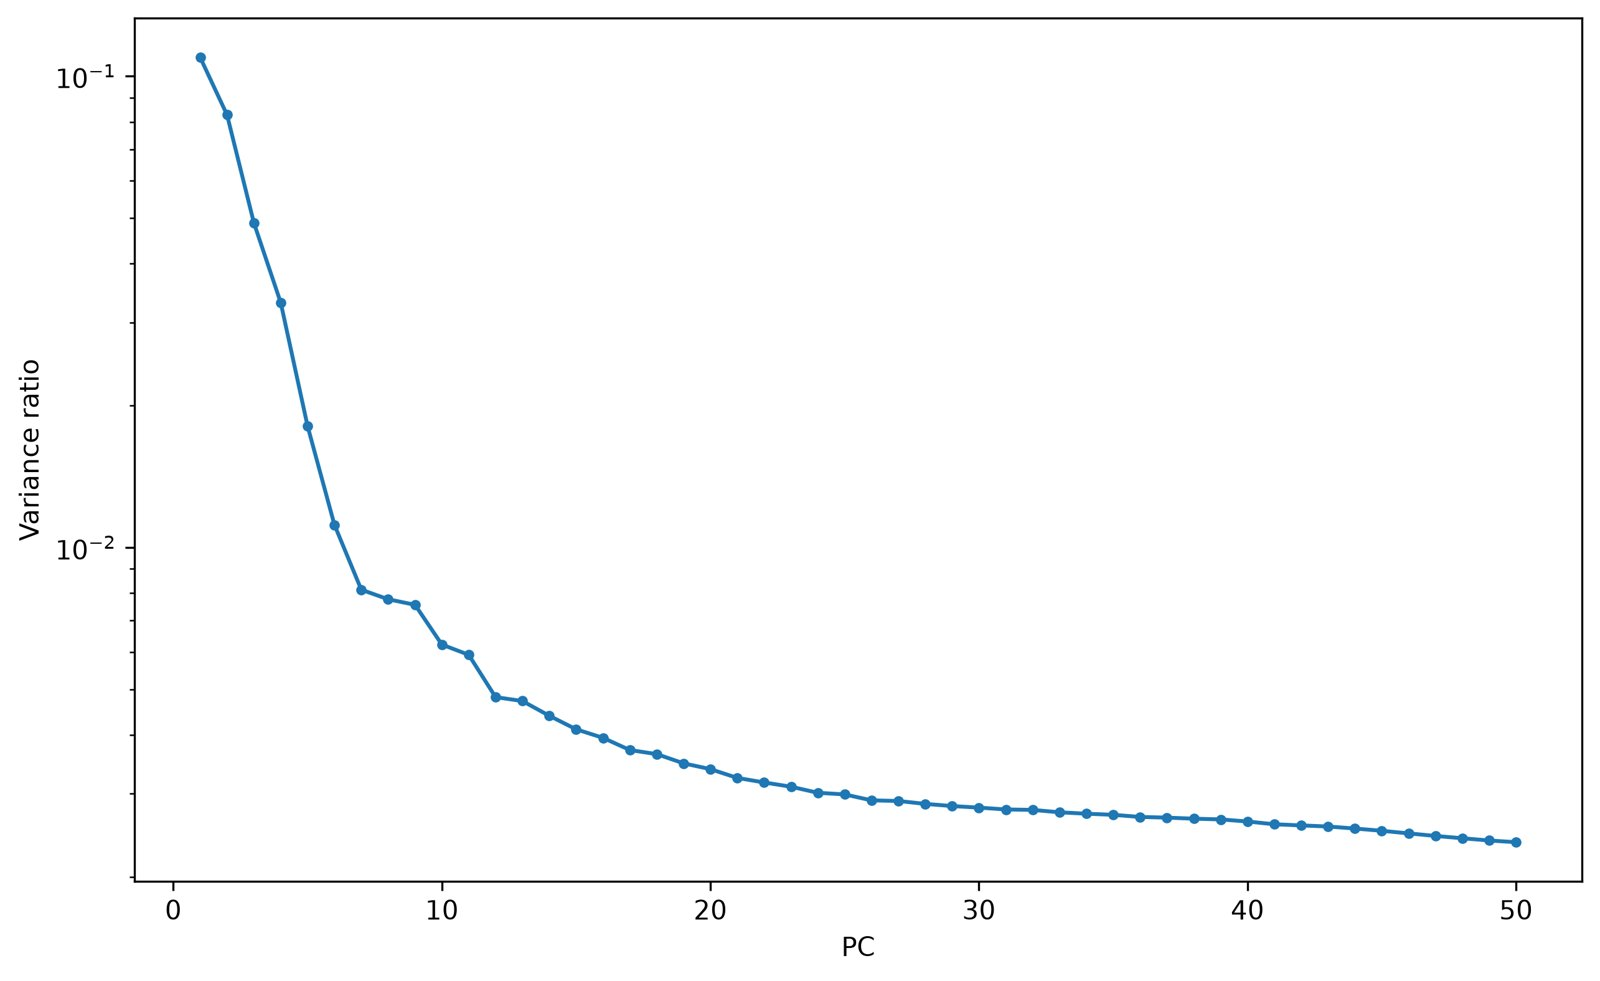

[Full-resolution figure](../figures/preprocess/pca/variance_ratio.png)

In [13]:
show("preprocess/pca/variance_ratio.png", width=650)

- **50 components computed on the 2,000 variable genes, without scaling**, so
  strongly varying genes such as HBB keep their weight.
- **Variance falls steeply over the first 6–7 components**, steps down again
  at 10–12, and is nearly flat after about 15 (log scale).
- **30 components were kept, not 20.** The later ones carry little variance
  but can hold rare progenitor structure, which the trajectory stage needed.

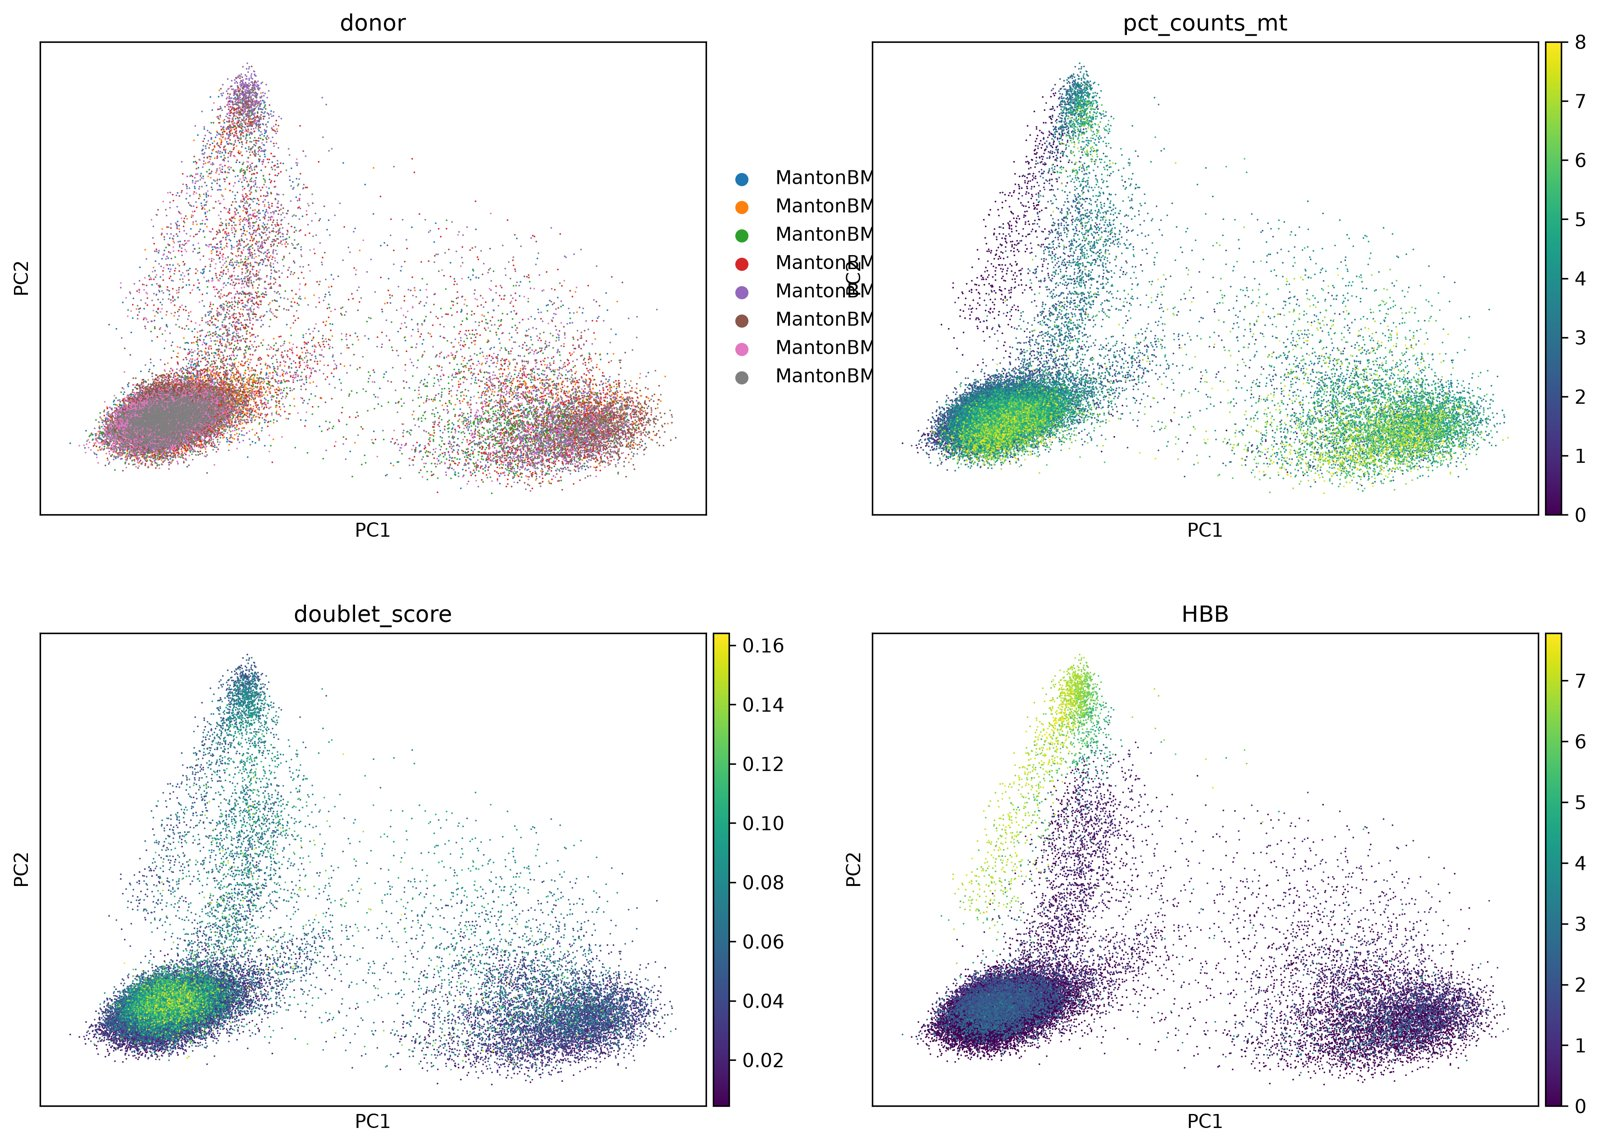

[Full-resolution figure](../figures/preprocess/pca/pca_overview.png)

In [14]:
show("preprocess/pca/pca_overview.png")

- **PC1 separates the lymphoid cloud (left) from the myeloid cloud (right);
  PC2 rises into the erythroid arm**, which is bright for HBB.
- **Donors are mixed everywhere** (top left). This was the first sign that the
  donor batch effect is weak, contradicting the original plan; the benchmark
  confirmed it.
- **The myeloid cloud is high on mitochondrial share** (top right): the
  monocytes, a property of the cell type that must not be filtered later.
- **Doublet score is highest inside the lymphoid cloud** (bottom left), not in
  any separate group — the first hint of the effect explained in section 5.

## 5. Clustering

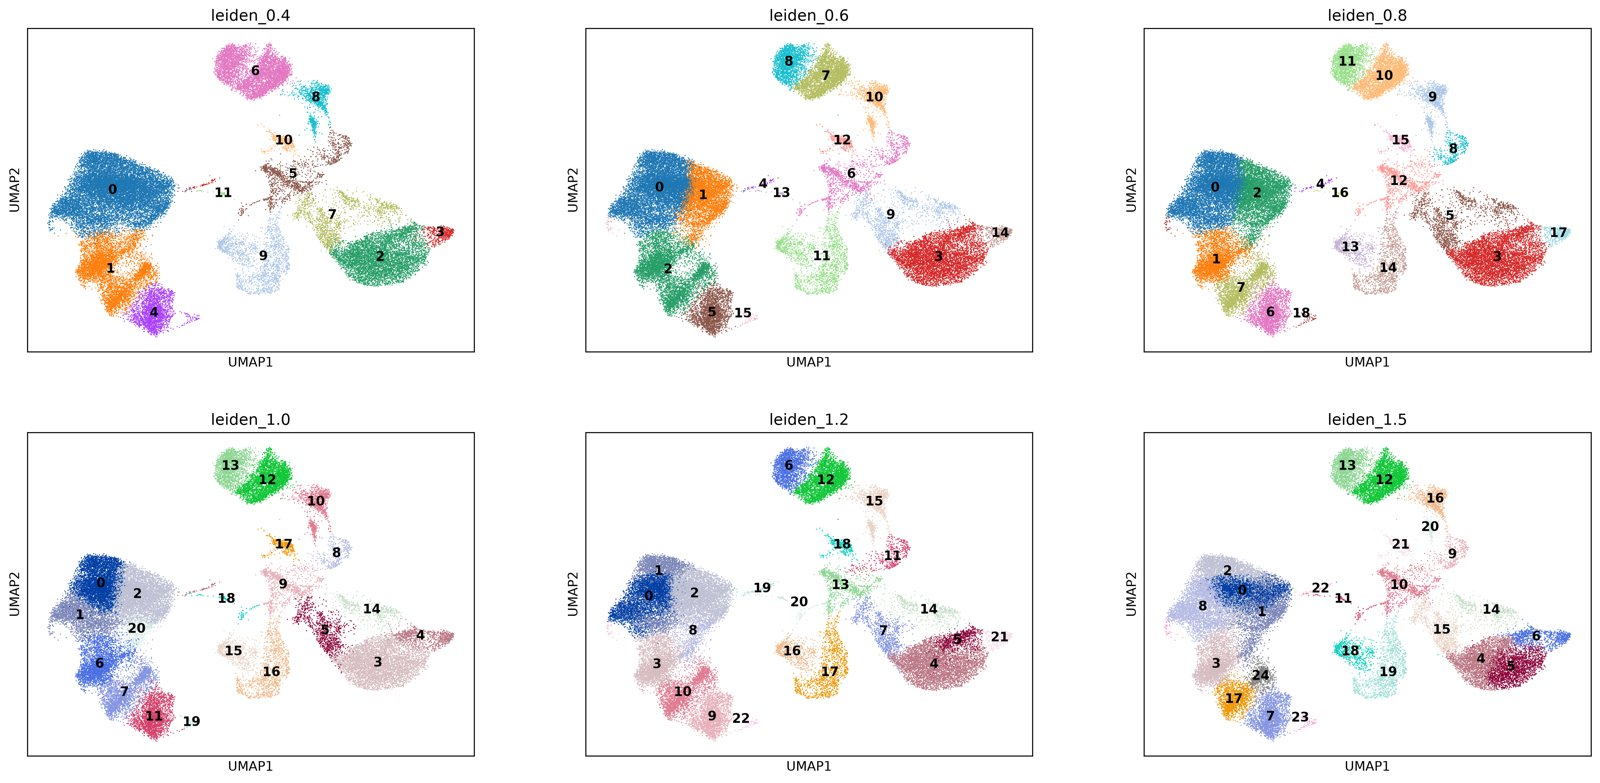

[Full-resolution figure](../figures/cluster/cluster/umap_leiden_grid.png)

In [15]:
show("cluster/cluster/umap_leiden_grid.png")

- **15 neighbours on 30 components; Leiden at six resolutions** gives 12, 16,
  19, 21, 23 and 25 clusters at 0.4, 0.6, 0.8, 1.0, 1.2 and 1.5. The count
  climbs steadily with no plateau, so it does not pick a resolution by itself.
- **Stable splits (real structure):** the B region splits in two from 0.6 on;
  the erythroid region splits into early and late from 0.8 on; the small
  MPO-high patch separates from 0.8 on.
- **Unstable splits (cuts through continuous clouds):** the T region goes from
  3 to 9 clusters and the monocyte region from 2 to 5, with no visible gaps.
  Resolutions 1.2 and 1.5 only add slivers inside these clouds.
- **Resolution 1.0 (21 clusters) was chosen**: merging two clusters later is
  one line; recovering a rare type swallowed at a lower resolution means
  re-running everything.

In [16]:
table("cluster/markers/cluster_summary_leiden_1.0.csv", index_col="leiden_1.0")

,cells,doublet_score,pct_counts_mt,n_genes_by_counts,pct_counts_hb,pct_counts_ribo
leiden_1.0,,,,,,
0,5005,0.06,2.76,756.88,0.03,52.18
1,2713,0.06,3.05,810.25,0.03,47.64
2,5760,0.05,2.92,551.42,0.03,52.46
3,5030,0.04,5.03,725.91,0.05,27.20
4,901,0.05,4.30,995.71,0.03,27.73
5,926,0.05,5.06,1074.49,0.03,36.14
6,2977,0.05,3.97,681.97,0.04,36.79
7,2307,0.05,3.95,699.62,0.03,34.92
8,334,0.08,2.58,2141.27,0.02,31.65


- **Cluster 16 averages 3,946 genes per cell with 9.6% haemoglobin**: the early
  erythroid lineage, i.e. the high-complexity cells flagged but kept in
  section 2.
- **Cluster 15 has 0.57% mitochondrial reads**, the lowest of all, with 11.3%
  haemoglobin: late red cells, which shed their mitochondria. Real biology.
- **Clusters 3, 4 and 5 sit at 4.3–5.1% mitochondrial reads** (monocytes and
  granulocyte precursors): a property of the cell type.
- **Clusters 8, 9, 14 and 19 have about 1,960–2,290 genes per cell**: cycling
  pre-B, HSPC, dendritic cells and dividing T cells — large, active cells.
- **Clusters 0, 1, 2, 9, 12, 13 and 20 carry 46.5–52.5% ribosomal reads**;
  this later hijacked the first marker test (section 6).
- **Doublet score is 0.03–0.09 in every cluster**: no cluster is driven by
  doublets.
- **Cluster 18 (103 cells) and 19 (47 cells) are the smallest**: every later
  result on them rests on few cells.

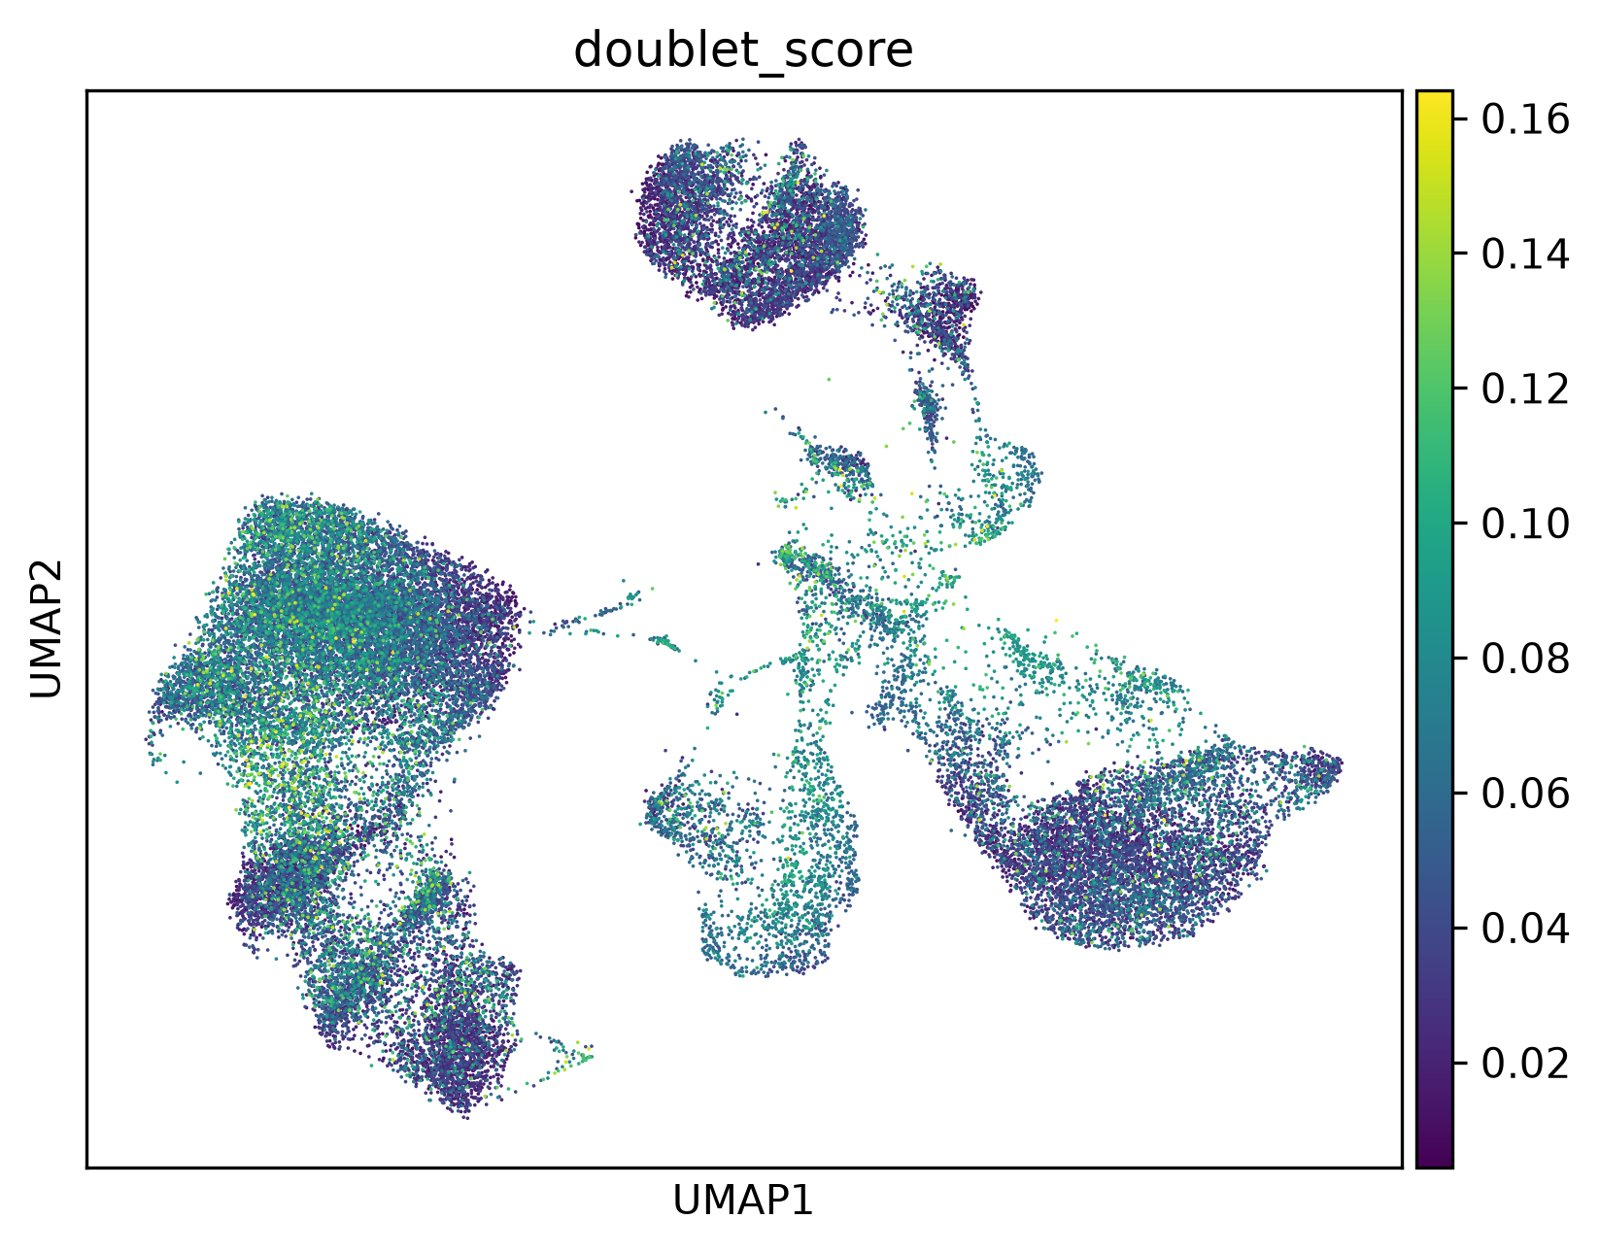

[Full-resolution figure](../figures/cluster/cluster/umap_doublet_score.png)

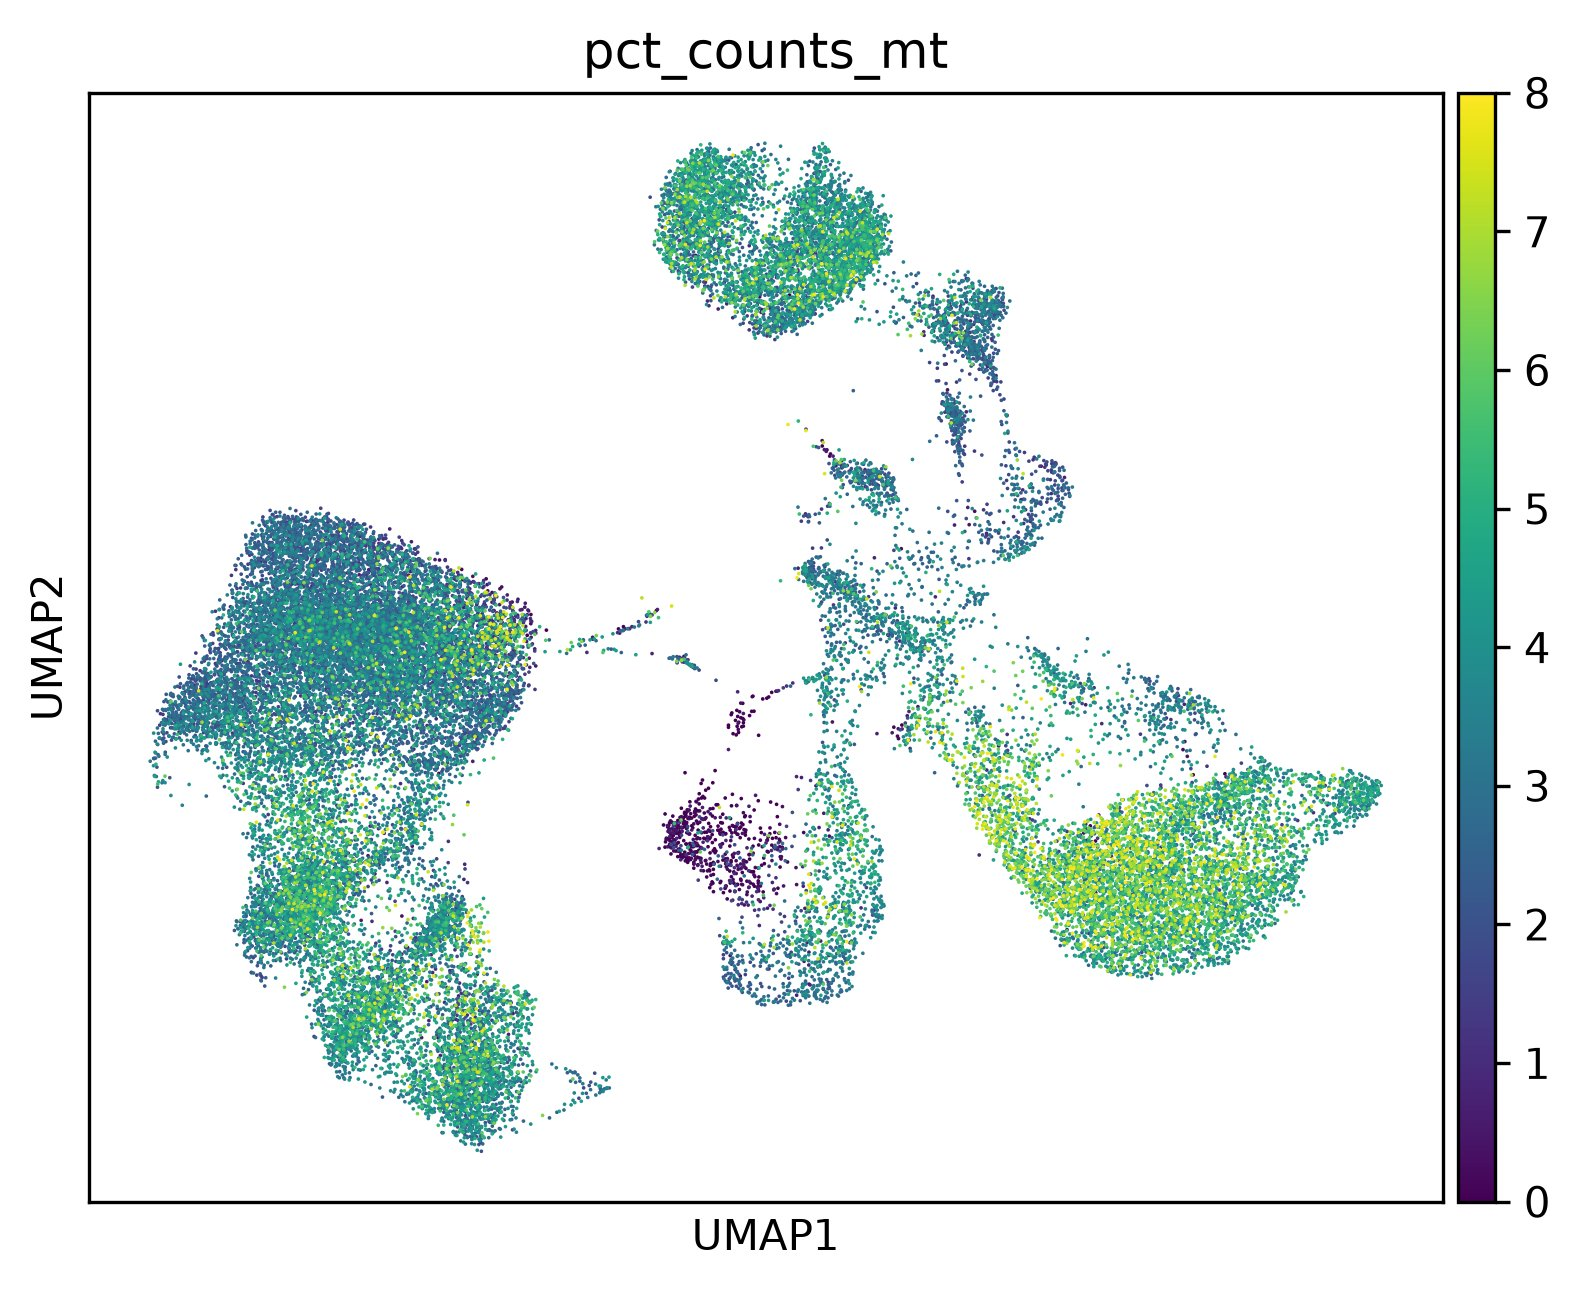

[Full-resolution figure](../figures/cluster/cluster/umap_pct_counts_mt.png)

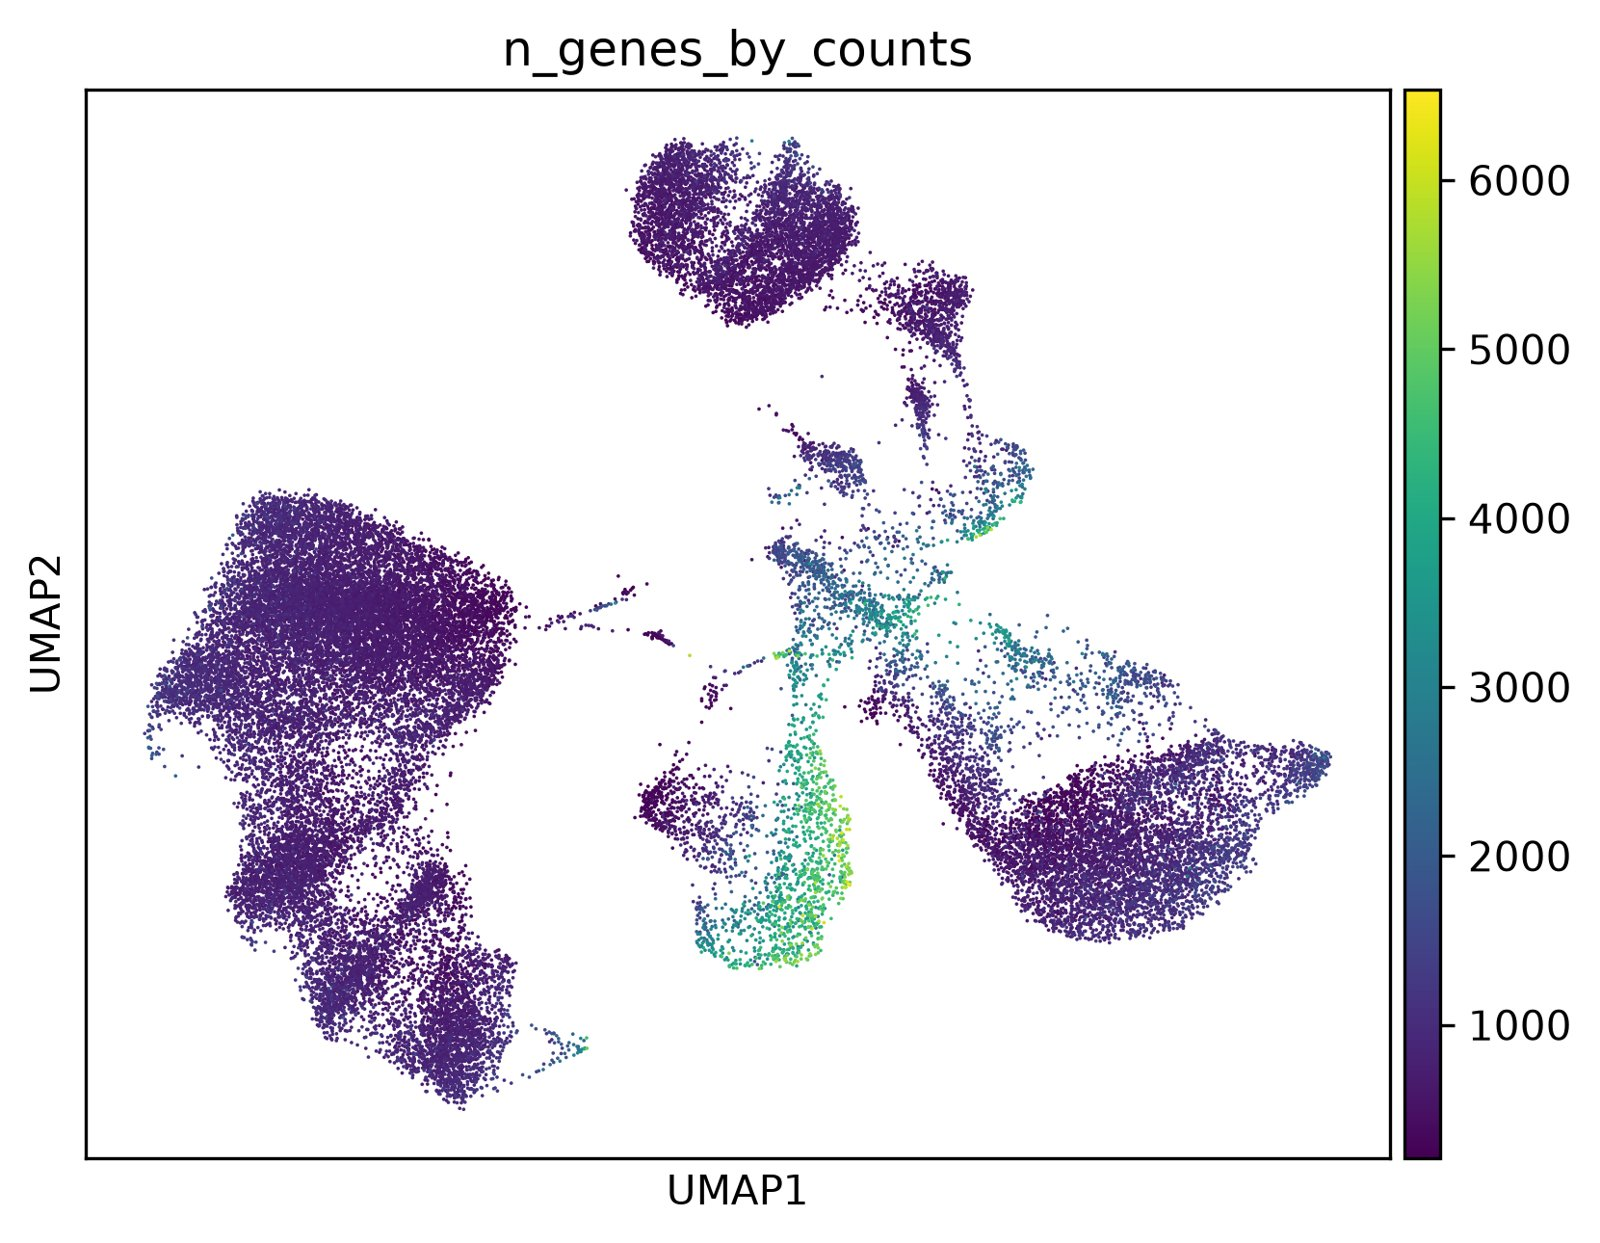

[Full-resolution figure](../figures/cluster/cluster/umap_n_genes_by_counts.png)

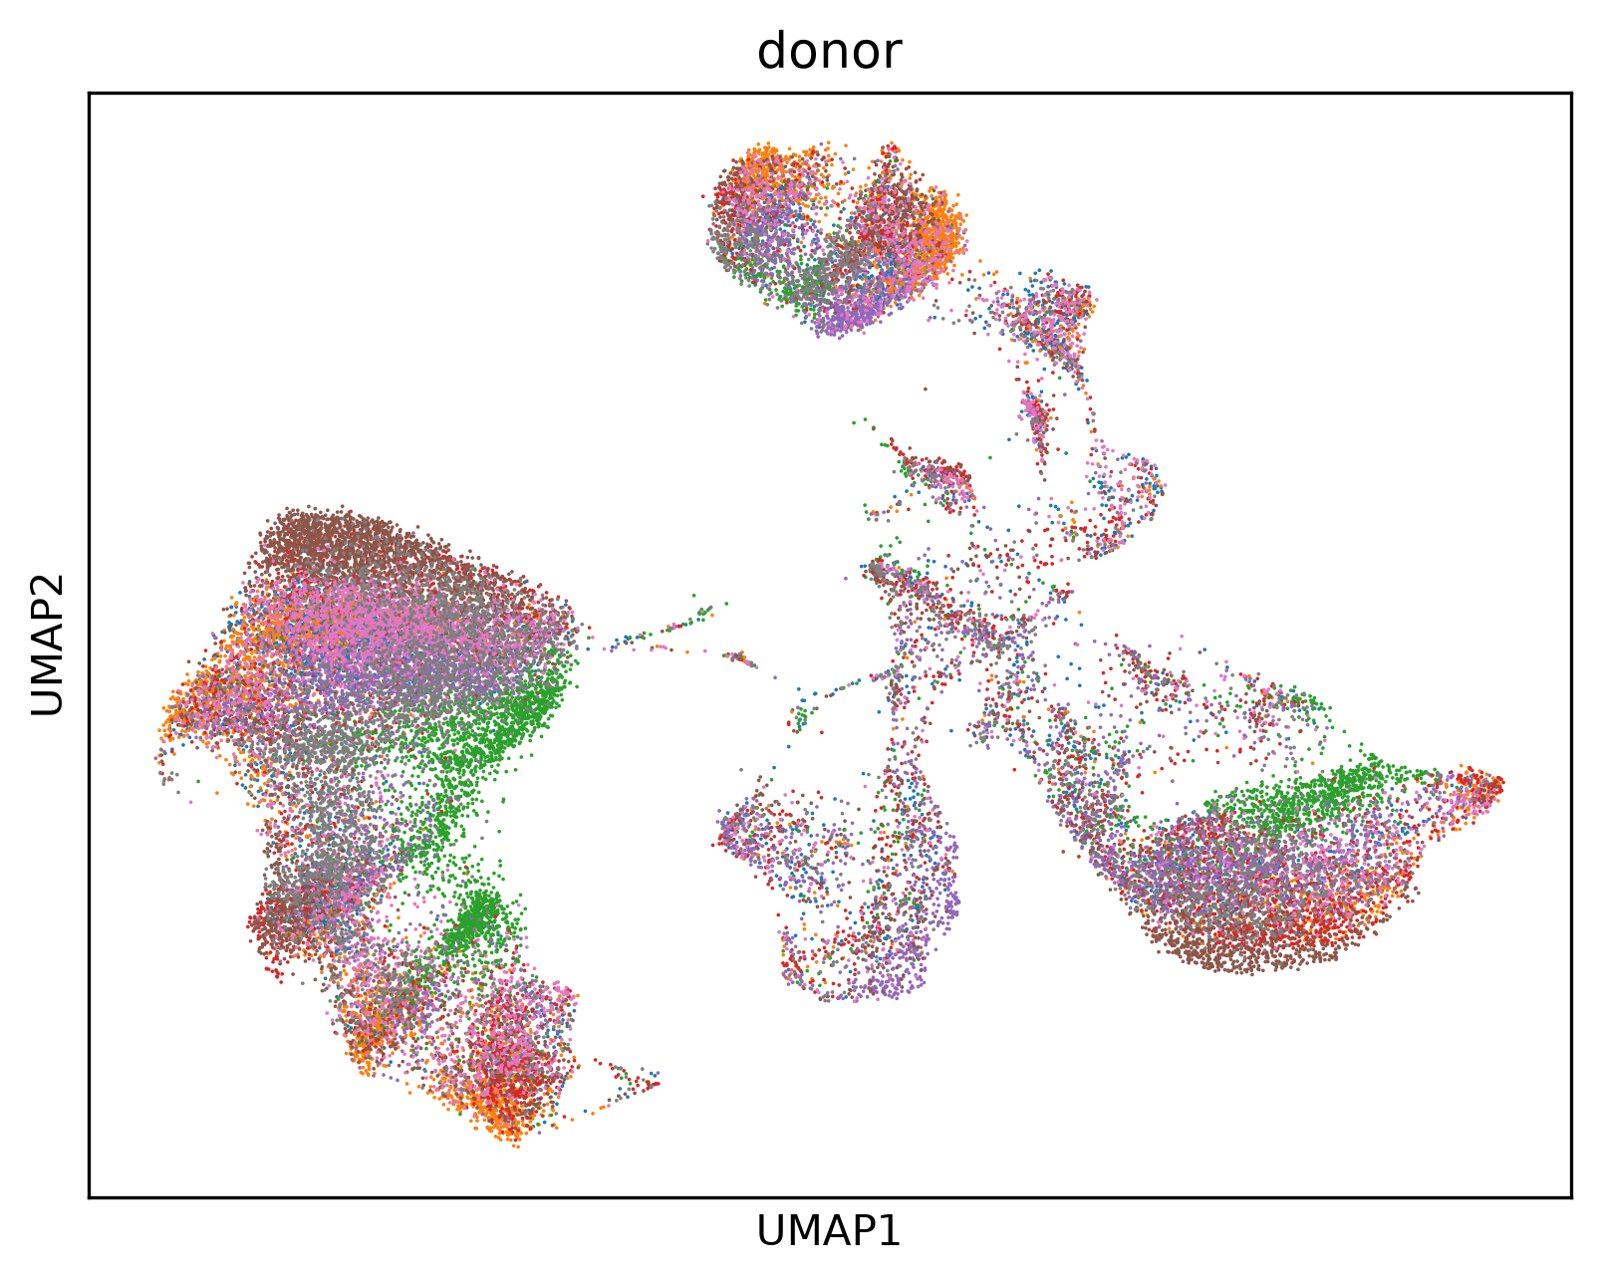

[Full-resolution figure](../figures/cluster/cluster/umap_donor.png)

In [17]:
for name in ("doublet_score", "pct_counts_mt", "n_genes_by_counts", "donor"):
    show(f"cluster/cluster/umap_{name}.png", width=560)

- **Doublet score is raised across the whole T region**, not in one cluster.
  Cells between closely related states look like mixtures to Scrublet; this is
  not a doublet cluster and nothing was removed for it.
- **The monocyte region is uniformly high on mitochondrial share (6–8%)**, and
  the late erythroid cells are the one region near 0%.
- **Gene counts are highest in the erythroid island and the progenitor
  bridges** (up to about 6,000 genes); the T, B and monocyte regions sit near
  700–1,000.
- **Donors are mixed in every region**, with one exception: green
  (MantonBM3, scanpy's default colours; the figure has no legend) forms a
  streak along the right edge of the T region and a band across the top of the
  monocyte region. Later stages found MantonBM3 holds 532 of the 583 T
  activated cells and 45% of the non-classical monocytes.

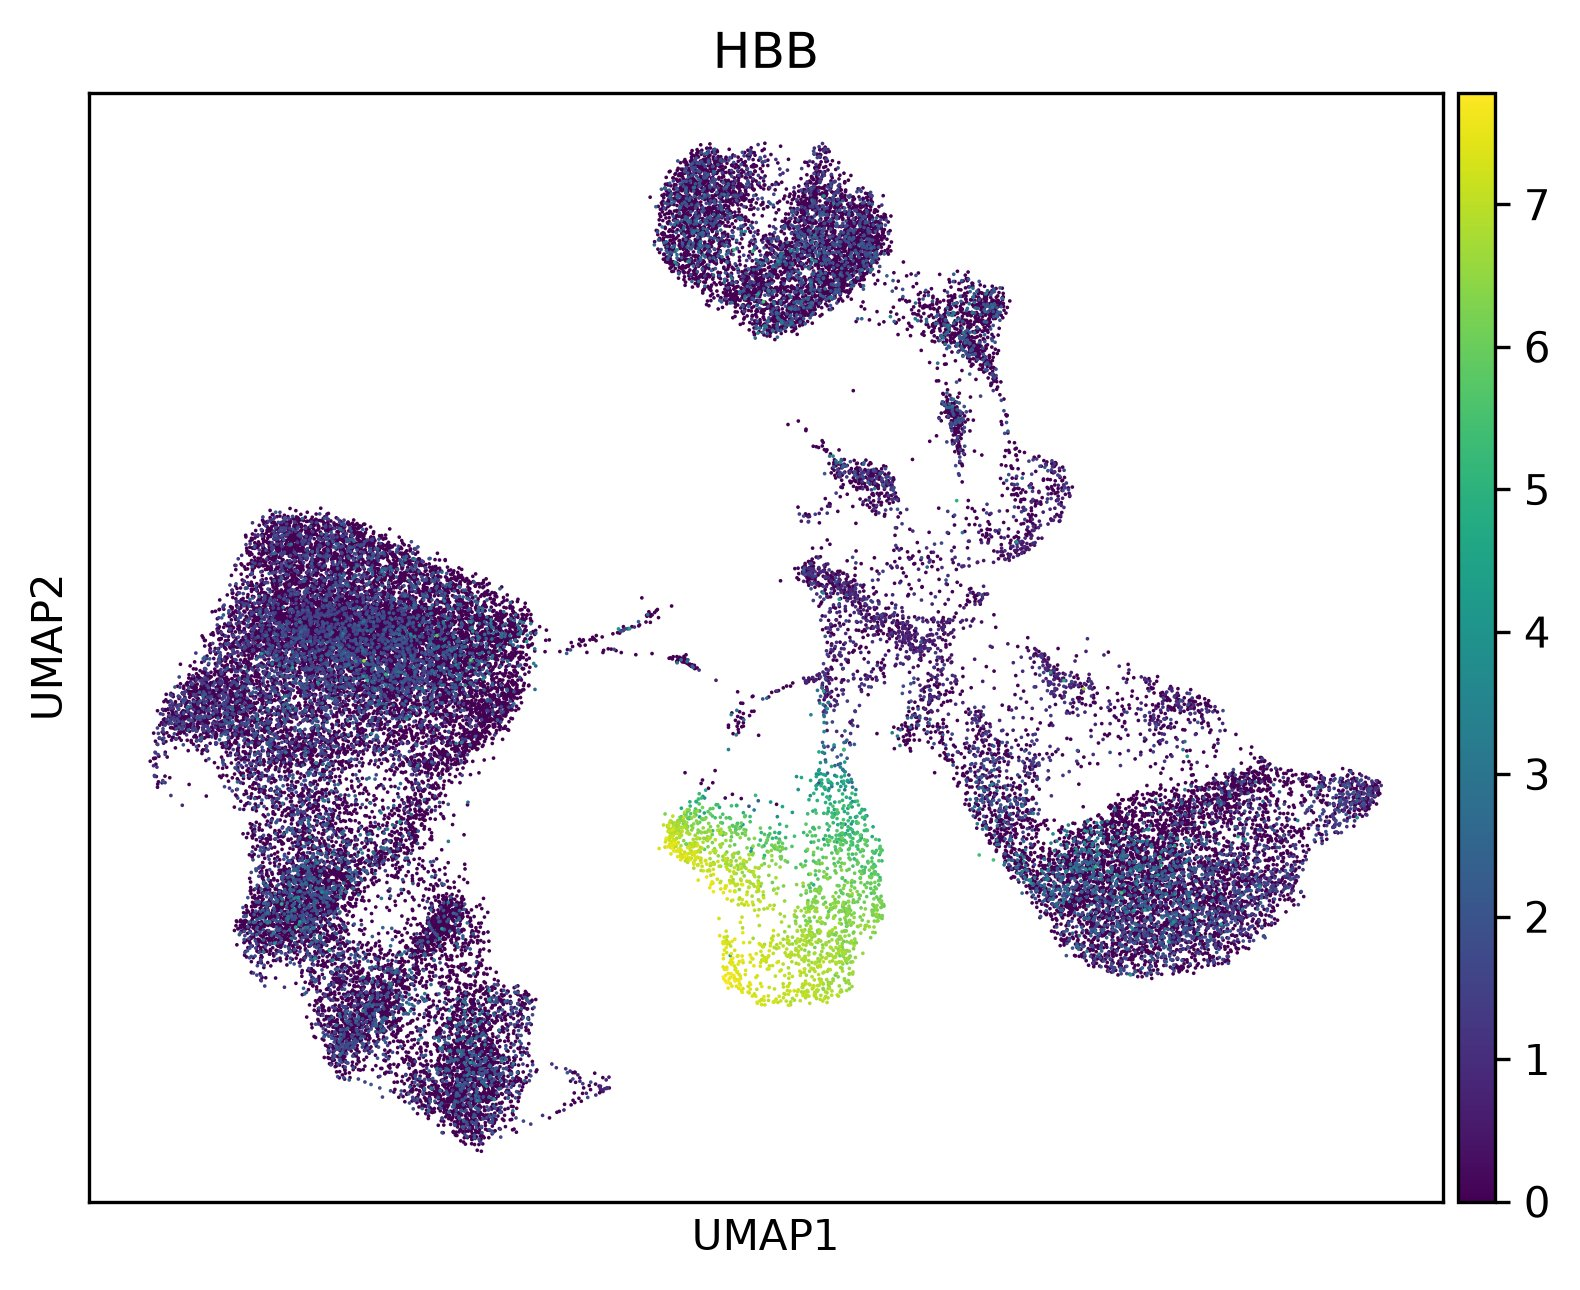

[Full-resolution figure](../figures/cluster/cluster/umap_HBB.png)

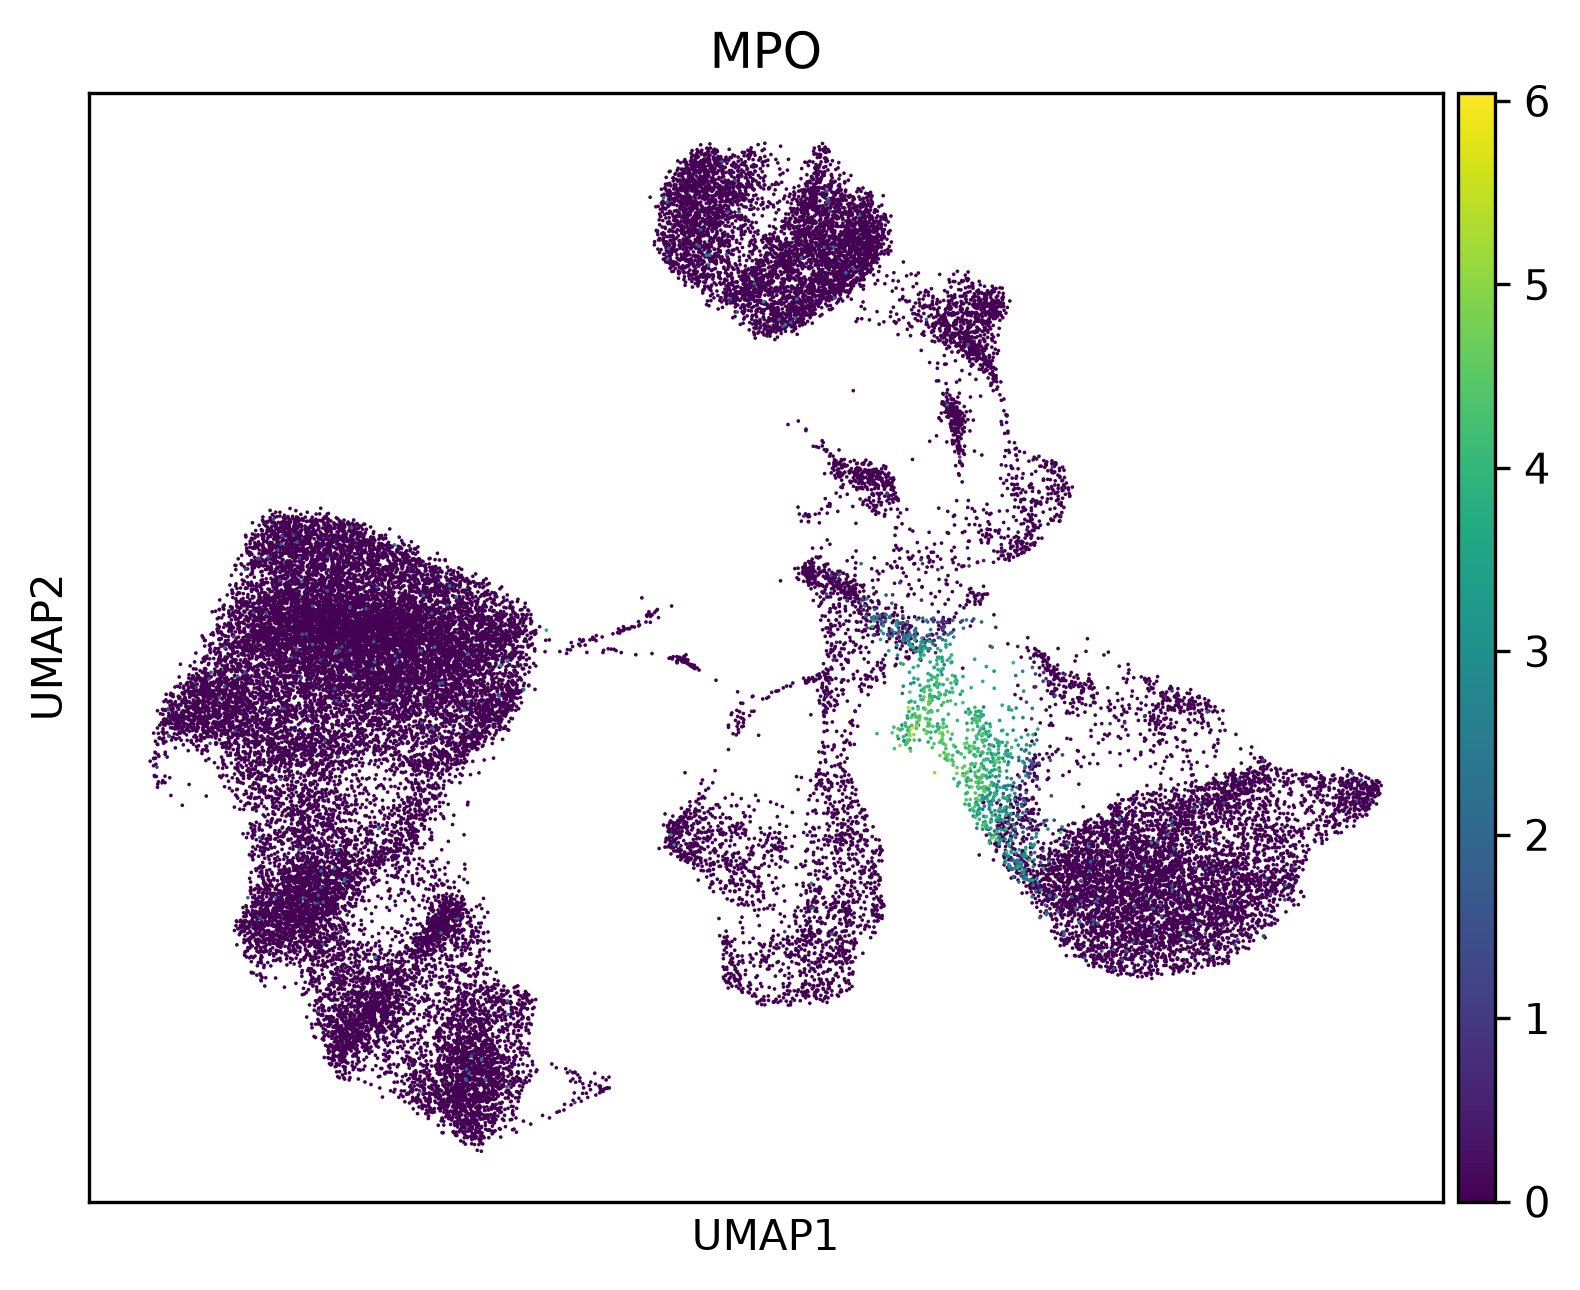

[Full-resolution figure](../figures/cluster/cluster/umap_MPO.png)

In [18]:
for gene in ("HBB", "MPO"):
    show(f"cluster/cluster/umap_{gene}.png", width=560)

- **HBB marks the erythroid island**, brightest at its lower and left edge (the
  late stage). Elsewhere it sits at a faint 1–2, the low background of free
  haemoglobin RNA in the droplets.
- **MPO marks only the narrow bridge from HSPC into the monocyte region**: the
  granulocyte precursors. Small, but separate from resolution 0.8 on.

## 6. Marker genes

In [19]:
markers = table("cluster/markers/markers_leiden_1.0_clean.csv")
markers.groupby("group").head(6).groupby("group")["names"].agg(", ".join).rename("top 6 markers")

group
0                 TRAC, EEF1A1, LTB, SARAF, CD3D, LDHB
1                     IL32, LTB, TRAC, IL7R, CD3D, B2M
2          MALAT1, SARAF, EEF1A1, LTB, LEPROTL1, EIF3E
3             S100A9, S100A8, FTL, LYZ, S100A6, TYROBP
4                    FTH1, FTL, SAT1, CST3, LST1, AIF1
5                  LYZ, SRGN, AZU1, RNASE2, MPO, H2AFZ
6                  CCL5, DUSP2, GZMK, B2M, HLA-A, IL32
7                   NKG7, CCL5, GNLY, GZMH, B2M, HLA-B
8             STMN1, HMGB1, PTMA, IGLL1, HMGN2, TUBA1B
9         NPM1, STMN1, HNRNPA1, SOX4, HSP90AB1, PRSS57
10            CD79B, VPREB3, PTMA, IGHM, SOX4, HLA-DRA
11                  NKG7, GNLY, B2M, CST7, GZMB, KLRB1
12          IGKC, CD74, HLA-DRA, CD79A, IGHM, HLA-DRB1
13             CD74, IGLC2, HLA-DRA, CD79A, IGHM, CD37
14    CST3, HLA-DPA1, HLA-DRA, HLA-DRB1, HLA-DPB1, VIM
15          AHSP, PRDX2, BLVRB, HMGB1, TUBA1B, ATP5IF1
16          BLVRB, PRDX2, AHSP, TMEM14C, KLF1, FAM178B
17         JCHAIN, ITM2C, SEC61B, C12orf75, CD74, NPC2
18  

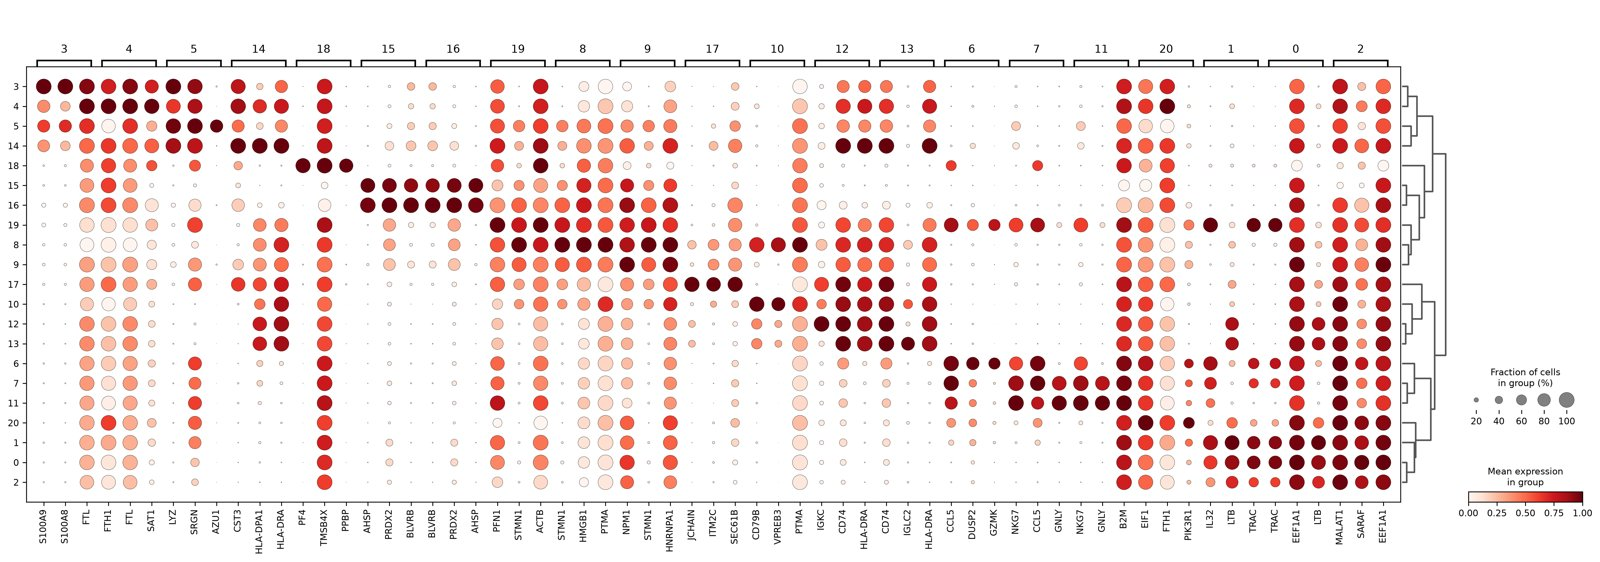

[Full-resolution figure](../figures/cluster/markers/dotplot_top3.png)

In [20]:
show("cluster/markers/dotplot_top3.png")

- **Wilcoxon test, each cluster against all other cells.**
- **The first run separated clusters by how busy they were, not by type:**
  clusters 0, 2 and 20 returned only RPS/RPL genes. Ribosomal, mitochondrial
  and haemoglobin genes were then dropped from the ranking; the clean table is
  shown, and the unfiltered one is kept on disk.
- **After the fix most identities are clear**: TRAC, CD3D, IL7R (T cells);
  S100A9, S100A8, LYZ (classical monocytes); LST1, AIF1 (non-classical
  monocytes); AZU1, MPO (granulocyte precursors); IGLL1 (cycling pre-B);
  SOX4, PRSS57 (HSPC); CD79B, VPREB3 (small pre-B); KLF1, AHSP (erythroid);
  JCHAIN (plasmacytoid DC); PF4, PPBP (platelets); GZMK (CD8 memory); NKG7,
  GNLY, GZMH (cytotoxic T and NK).
- **Housekeeping genes still lead several lists** (EEF1A1, MALAT1, FTL, FTH1,
  ACTB, PFN1, STMN1). A marker rank is relative to the other clusters, not
  proof of specificity.
- **Cluster 2 has no specific marker** (MALAT1, SARAF, EEF1A1, LTB) — it is the
  same naive T cells as cluster 0 at a different ribosomal level.
- **Cluster 20 rests on EIF1, FTH1, PIK3R1, HLA-B, MALAT1 and CD69**: no
  distinctive marker, only the activation gene CD69. This becomes the weakest
  label (T activated).

**Merge candidates** (pairs sharing 10 or more of their top 20 genes)

| pair | shared | decision |
|---|---|---|
| 0 + 2 | 15 (CD3D, CD3E, TRAC, IL7R, LTB …) | **merged** — same cells, split by ribosomal level |
| 12 + 13 | 18 (MS4A1, IGHD, CD79A, HLA-DR …) | **merged** — differ only by IGKC against IGLC2, i.e. kappa against lambda light chain, not a cell type |
| 3 / 4 | 11 | kept — classical against non-classical monocytes |
| 6 / 7 | 12 | kept — GZMK against GZMH CD8 states |
| 7 / 11 | 10 | kept — CD8 T against NK (KLRF1-positive, CD3-negative) |
| 15 / 16 | 10 | kept — two erythroid stages, 735 against 3,946 genes per cell |

## 7. Annotation

| label | clusters | key genes |
|---|---|---|
| CD4 T naive | 0, 2 | TRAC, CD3D, LTB, IL7R |
| CD4 T memory | 1 | IL32, IL7R, LTB |
| T activated | 20 | CD69, PIK3R1 |
| CD8 T memory | 6 | GZMK, CCL5, DUSP2 |
| CD8 T cytotoxic | 7 | GZMH, NKG7, GNLY |
| NK | 11 | NKG7, GNLY, KLRF1; CD3-negative |
| T proliferating | 19 | CD3D, TRAC with MKI67, PCLAF |
| Monocyte classical | 3 | S100A8, S100A9, LYZ |
| Monocyte non-classical | 4 | LST1, AIF1, CST3 |
| Dendritic cell | 14 | FCER1A, CST3, HLA class II |
| Plasmacytoid DC | 17 | JCHAIN, IRF7, MZB1 |
| Granulocyte precursor | 5 | MPO, AZU1, ELANE |
| HSPC | 9 | SOX4, PRSS57 |
| Pre-B large | 8 | IGLL1, VPREB1, MKI67 |
| Pre-B small | 10 | CD79B, VPREB3, IGHM |
| B naive | 12, 13 | MS4A1, IGHD, CD79A |
| Erythroid early | 16 | KLF1, FAM178B, AHSP |
| Erythroid late | 15 | AHSP, CA1, HBB |
| Platelet | 18 | PF4, PPBP, GP9 |

In [21]:
cell_types = table("annotate/core_pipeline_report/core_pipeline_report_cell_types.csv",
                   index_col="cell_type")
cell_types.assign(share=cell_types["total"] / cell_types["total"].sum())

,MantonBM1,MantonBM2,MantonBM3,MantonBM4,MantonBM5,MantonBM6,MantonBM7,MantonBM8,total,share
cell_type,,,,,,,,,,
HSPC,105,26,79,184,176,138,90,175,973,0.025
Granulocyte precursor,126,29,120,148,211,116,39,137,926,0.024
Monocyte classical,366,385,616,1070,842,656,386,709,5030,0.131
Monocyte non-classical,32,118,401,138,81,18,77,36,901,0.023
Dendritic cell,33,14,92,91,70,59,55,83,497,0.013
Plasmacytoid DC,26,19,41,83,37,35,50,39,330,0.009
Erythroid early,121,54,57,172,407,151,73,116,1151,0.030
Erythroid late,106,34,24,87,146,71,71,58,597,0.016
Platelet,18,22,17,4,6,14,14,8,103,0.003


- **21 clusters → 19 labels, 38,430 cells, none unlabelled.**
- **The dataset is dominated by four labels**: CD4 T naive 28.0%, B naive
  13.1%, Monocyte classical 13.1%, CD8 T memory 7.7% — 62% together.
- **Four labels are under 1%**: Plasmacytoid DC 330, Pre-B large 334,
  Platelet 103 and T proliferating 47.
- **Donor composition is very uneven, even though the batch effect is weak.**
  An even split would give each donor 12.5% of a label; the largest single
  donor holds 18.5–47% of every label except one, and the median is 25%.
- **T activated is 91.3% one donor**: 532 of 583 cells are MantonBM3, and four
  donors have 0 or 1 cell. With markers resting on CD69 alone, it is the
  weakest of the 19 labels — kept by the project's rule that labels stay fixed,
  and flagged in every later stage.
- **Other concentrations to keep in mind**: T proliferating 46.8% MantonBM4,
  Monocyte non-classical 44.5% MantonBM3, CD8 T cytotoxic and Erythroid early
  35.4% each (MantonBM3 and MantonBM5).
- **Corrected after CellTypist (section 8):** clusters 8 and 10 were first
  called "Pro-B" and "Pre-B"; cluster 19 was first called "Proliferating"
  before its CD3D/TRAC signal was read.

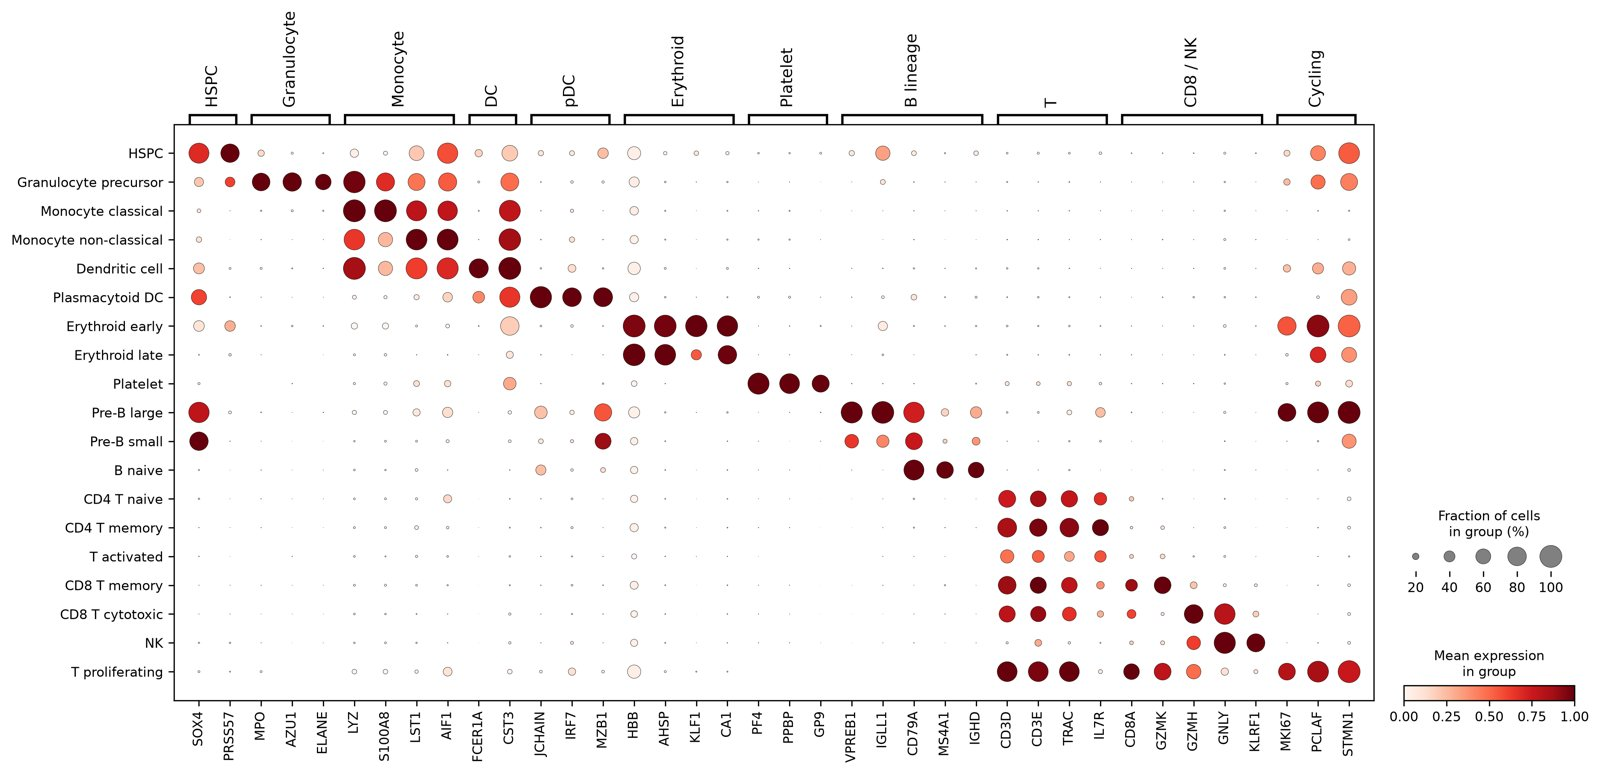

[Full-resolution figure](../figures/annotate/annotate/dotplot_canonical.png)

In [22]:
show("annotate/annotate/dotplot_canonical.png")

- **Every marker block lights up in its own rows and almost nowhere else**, so
  the labels hold against textbook markers chosen in advance.
- **The cycling block (MKI67, PCLAF, STMN1) is strongest in the dividing
  labels**: Pre-B large, T proliferating and Erythroid early, weaker in HSPC
  and the granulocyte precursors.
- **SOX4 is shared by HSPC and the pre-B labels**, as expected for early
  progenitors; PRSS57 is specific to HSPC.
- **T activated is the palest T row**: it expresses the T genes, but more
  weakly than its neighbours, with no block of its own.
- **Erythroid late is KLF1-low and HBB/AHSP/CA1-high**, Erythroid early the
  reverse balance: the two stages separate on the expected genes.

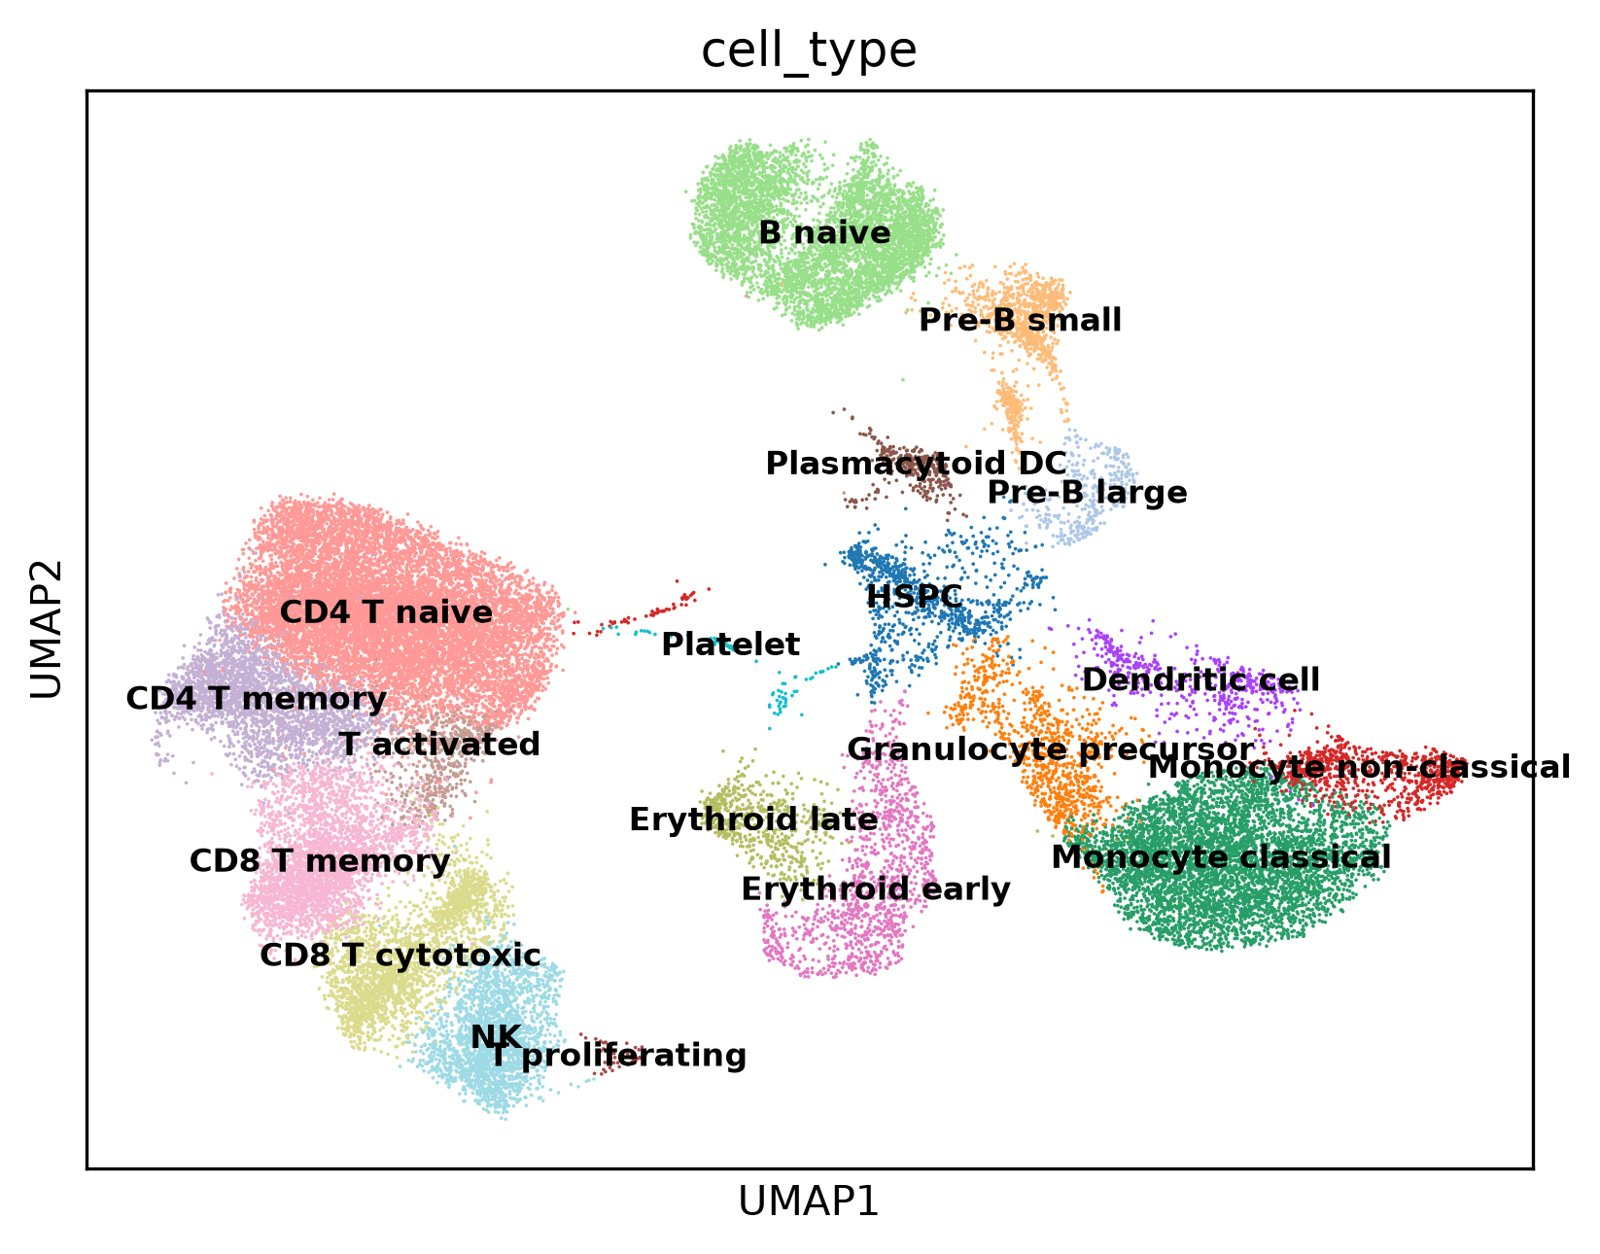

[Full-resolution figure](../figures/annotate/annotate/umap_cell_type.png)

In [23]:
show("annotate/annotate/umap_cell_type.png", width=750)

- **Lymphoid labels on the left, myeloid on the right, B lineage at the top,
  erythroid at the bottom centre, with HSPC in the middle** — the
  differentiation branches are visible as bridges from HSPC (to granulocyte
  precursors and monocytes, to pre-B, to erythroid).
- **The mature T and NK cells form a separate island, not connected to
  HSPC**; B naive connects only through the pre-B cells. These cells were
  collected as finished cells; the trajectory stage reports this as a negative
  result.
- **Platelets form a thin scattered streak between the T region and HSPC**,
  consistent with very small, low-RNA cells.

## 8. CellTypist cross-check

In [24]:
celltypist = table("annotate/celltypist_check/celltypist_vs_manual.csv", index_col="cell_type")
pd.DataFrame({
    "CellTypist call": celltypist.idxmax(axis=1),
    "share": celltypist.max(axis=1) / celltypist.sum(axis=1),
    "cells": celltypist.sum(axis=1),
})

,CellTypist call,share,cells
cell_type,,,
HSPC,HSC/MPP,1.0,973
Granulocyte precursor,Classical monocytes,1.0,926
Monocyte classical,Classical monocytes,1.0,5030
Monocyte non-classical,Non-classical monocytes,1.0,901
Dendritic cell,DC2,1.0,497
Plasmacytoid DC,pDC,1.0,330
Erythroid early,Mid erythroid,1.0,1151
Erythroid late,Mid erythroid,1.0,597
Platelet,Megakaryocytes/platelets,1.0,103


- **Model `Immune_All_Low.pkl` with majority voting over the Leiden
  clusters**; 5,658 of the 20,455 genes matched the model.
- **Every share is 100%, and that is expected, not a result**: majority voting
  gives every cell in a cluster the same call. It checks cluster identity,
  not single cells.
- **One-to-one agreement**: HSPC (HSC/MPP), both monocytes, dendritic cell
  (DC2), plasmacytoid DC, platelet, Pre-B large, Pre-B small, B naive,
  CD8 T memory (Tem/Trm cytotoxic), CD8 T cytotoxic (Tem/Temra), NK (CD16+ NK).
- **Granulocyte precursor → "Classical monocytes"**: our label stands. The
  cluster carries MPO, AZU1, ELANE and PRTN3; the blood-trained model has no
  granulocyte precursor class.
- **Erythroid early and late → both "Mid erythroid"**: our split stands; the
  model's erythroid stages are coarser than the data (735 against 3,946 genes
  per cell, KLF1 against AHSP/CA1).
- **CD4 T naive, CD4 T memory and T activated → all "Tcm/Naive helper T
  cells"**: the model does not separate them. For T activated this is a further
  strike against the label.
- **T proliferating → "Tem/Trm cytotoxic T cells"**: the model has no cycling
  class; the 47 cells are MKI67 and PCLAF positive.
- **The CellTypist names confirmed two renames**: "Large pre-B cells" and
  "Small pre-B cells" matched the marker evidence better than the original
  "Pro-B" and "Pre-B".

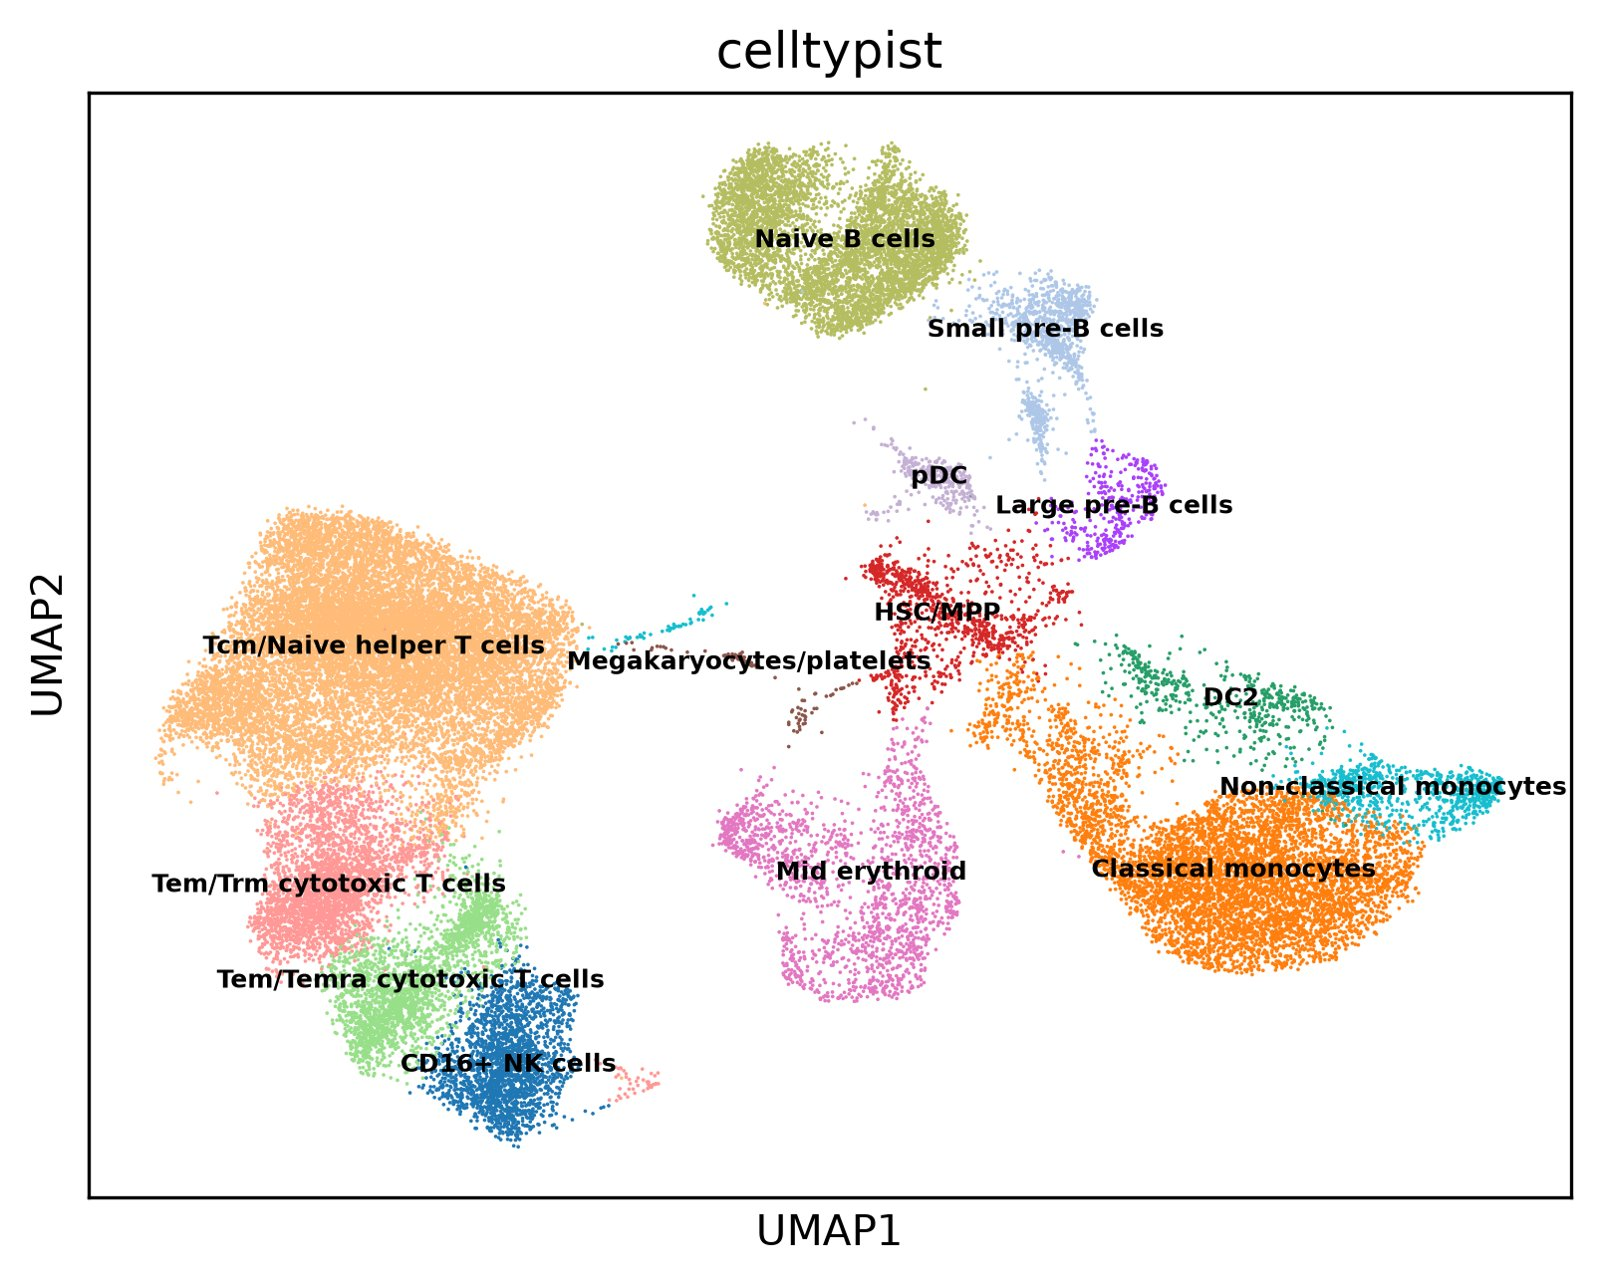

[Full-resolution figure](../figures/annotate/celltypist_check/umap_celltypist.png)

In [25]:
show("annotate/celltypist_check/umap_celltypist.png", width=750)

- **The CellTypist map repeats the same islands with 14 classes** instead of
  19: one large helper-T region, one "Mid erythroid" island, the granulocyte
  bridge absorbed into "Classical monocytes".
- **Every other boundary matches the manual labels.**

## 9. What every later stage inherits

- **`data/processed/bm_annotated.h5ad`**: 38,430 cells × 20,455 genes, 19
  labels, raw counts in `layers["counts"]`, `X_pca` (30 components used) and
  `X_umap`. Nothing downstream writes back into it, and the labels stay fixed.
- **Settings reused downstream**: 2,000 variable genes (`seurat_v3`, per donor),
  30 components, 15 neighbours, Leiden resolution 1.0, seed 7.
- **Rules learned**:
  - Scrublet's automatic threshold is unusable on this shallow data; use the
    per-donor top-4% rule.
  - Drop ribosomal, mitochondrial and haemoglobin genes from marker rankings.
  - Do not filter high-gene cells (early erythroid) or high-mitochondrial
    groups (monocytes) later — both are real.
- **Known weak points**:
  - T activated is 91% one donor and rests on CD69; read any result on it as a
    MantonBM3 result.
  - Platelet (103) and T proliferating (47) are too small for firm results.
  - Three real cell types are missing from the labels — plasma cells, mast
    cells / basophils and macrophages, found later by cNMF; they sit inside
    larger clusters.